# Stage 1: Data Collection

### 1a. Importing Libraries

Load the core Python libraries (pandas, numpy, matplotlib/seaborn) needed for data handling and visualisation throughout the notebook.

In [ ]:
import json
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)

print("Libraries Loaded Successfully")

Libraries Loaded Successfully


### 1b.Loading the dataset and Inspect Dataset Structure


Load the raw IoT sensor CSV export and take a first look at its shape and columns.

In [ ]:
df = pd.read_csv('/content/Dataset (2).csv')
print(df.shape)
df.head()

(12587, 7)


,tsmeasuredat,tenant,deviceid,location,payload,meta,ts_ingested_db
0,2026-07-21 09:10:12+00,franey-foods,current-01,knockmitten,"{""IMEI"": ""861562073835545"", ""IMSI"": ""901288937...","{""sb"": {""message_id"": ""764866f2fcc7752c7fa07bd...",2026-07-21 09:11:22.23582+00
1,2026-07-21 08:55:12+00,franey-foods,current-01,knockmitten,"{""IMEI"": ""861562073835545"", ""IMSI"": ""901288937...","{""sb"": {""message_id"": ""764866f2fcc7752c7fa07bd...",2026-07-21 09:11:22.23582+00
2,2026-07-21 08:40:12+00,franey-foods,current-01,knockmitten,"{""IMEI"": ""861562073835545"", ""IMSI"": ""901288937...","{""sb"": {""message_id"": ""764866f2fcc7752c7fa07bd...",2026-07-21 09:11:22.23582+00
3,2026-07-21 08:25:12+00,franey-foods,current-01,knockmitten,"{""IMEI"": ""861562073835545"", ""IMSI"": ""901288937...","{""sb"": {""message_id"": ""764866f2fcc7752c7fa07bd...",2026-07-21 09:11:22.23582+00
4,2026-07-21 08:10:12+00,franey-foods,current-01,knockmitten,"{""IMEI"": ""861562073835545"", ""IMSI"": ""901288937...","{""sb"": {""message_id"": ""764866f2fcc7752c7fa07bd...",2026-07-21 09:11:22.23582+00


### 1c. Dataset Information

Check column data types and non-null counts to spot obvious data-quality issues before going further.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12587 entries, 0 to 12586
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   tsmeasuredat    12587 non-null  object
 1   tenant          12587 non-null  object
 2   deviceid        12587 non-null  object
 3   location        12587 non-null  object
 4   payload         12587 non-null  object
 5   meta            12587 non-null  object
 6   ts_ingested_db  12587 non-null  object
dtypes: object(7)
memory usage: 688.5+ KB


No missing values are found

### 1d.Basic Summary

 Get summary statistics (mean, std, min/max, etc.) for every column to understand the value ranges being worked with.

In [ ]:
df.describe(include='all')

,tsmeasuredat,tenant,deviceid,location,payload,meta,ts_ingested_db
count,12587,12587,12587,12587,12587,12587,12587
unique,12587,1,1,1,12587,810,810
top,2026-01-30 09:50:35+00,franey-foods,current-01,knockmitten,"{""IMEI"": ""861562073835545"", ""IMSI"": ""901288937...","{""sb"": {""message_id"": ""13847f4305d03e93e356a75...",2026-01-31 16:51:45.657682+00
freq,1,12587,12587,12587,1,16,16


`tsmeasuredat` → looks like a timestamp, but stored as a string

`payload` → looks like JSON, but stored as a string

`meta` → also JSON-like, but stored as a string

`ts_ingested_db` → timestamp, but stored as a string

The raw IoT dataset contained 12,587 readings collected at 15-minute intervals from a commercial building current monitoring sensor. The dataset initially consisted of 7 columns, including timestamps, metadata attributes, and a payload field containing sensor measurements in JSON format.

# Stage 2: Data Preprocessing

### 2a. Expand Payload JSON

In [ ]:
payload_df = (
    df['payload']
    .apply(json.loads)
    .apply(pd.Series)
)

df = pd.concat(
    [
        df.drop(columns=['payload', 'meta']),
        payload_df
    ],
    axis=1
)

print(df.shape)
df.head()

(12587, 20)


,tsmeasuredat,tenant,deviceid,location,ts_ingested_db,IMEI,IMSI,type,Model,signal,battery,sample_ts,current_chan1,current_chan2,current_chan3,current_chan4,assumed_voltage_v,real_power_total_kW,assumed_power_factor,assumed_noise_floor_a
0,2026-07-21 09:10:12+00,franey-foods,current-01,knockmitten,2026-07-21 09:11:22.23582+00,861562073835545,901288937108331,dragino-cs01-nb-current,CS01-NB,17,3.626,2026-07-21T09:10:12+00:00,52.518,54.066,55.953,0.018,NaN,NaN,NaN,NaN
1,2026-07-21 08:55:12+00,franey-foods,current-01,knockmitten,2026-07-21 09:11:22.23582+00,861562073835545,901288937108331,dragino-cs01-nb-current,CS01-NB,17,3.626,2026-07-21T08:55:12+00:00,53.345,54.700,56.638,0.018,NaN,NaN,NaN,NaN
2,2026-07-21 08:40:12+00,franey-foods,current-01,knockmitten,2026-07-21 09:11:22.23582+00,861562073835545,901288937108331,dragino-cs01-nb-current,CS01-NB,17,3.626,2026-07-21T08:40:12+00:00,54.302,56.313,58.130,0.018,NaN,NaN,NaN,NaN
3,2026-07-21 08:25:12+00,franey-foods,current-01,knockmitten,2026-07-21 09:11:22.23582+00,861562073835545,901288937108331,dragino-cs01-nb-current,CS01-NB,17,3.626,2026-07-21T08:25:12+00:00,1.077,6.128,0.015,0.018,NaN,NaN,NaN,NaN
4,2026-07-21 08:10:12+00,franey-foods,current-01,knockmitten,2026-07-21 09:11:22.23582+00,861562073835545,901288937108331,dragino-cs01-nb-current,CS01-NB,17,3.626,2026-07-21T08:10:12+00:00,1.081,6.139,0.016,0.018,NaN,NaN,NaN,NaN


Each row's real measurements are packed inside a JSON string in the `payload` column - expand each key into its own column.

### 2b. Convert Timestamps

In [ ]:
df['tsmeasuredat'] = pd.to_datetime(df['tsmeasuredat'], utc=True)
df['sample_ts'] = pd.to_datetime(df['sample_ts'], utc=True)
df['ts_ingested_db'] = pd.to_datetime(df['ts_ingested_db'], utc=True)
df = df.sort_values('sample_ts').reset_index(drop=True)

Time-series models require data in time order, the initial string is changed to time series

### 2c. Check Date Range

Confirm the exact start and end dates covered by the sensor data, since this defines the forecasting window available.

In [ ]:
print(
    "Start:",
    df['sample_ts'].min()
)

print(
    "End:",
    df['sample_ts'].max()
)

Start: 2026-01-30 09:50:35+00:00
End: 2026-07-21 09:10:12+00:00


In [ ]:
df['sample_ts'].dt.to_period('M').value_counts().sort_index()

/tmp/ipykernel_784/206686185.py:1: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df['sample_ts'].dt.to_period('M').value_counts().sort_index()


,count
sample_ts,
2026-01,46
2026-02,969
2026-03,1920
2026-04,1999
2026-05,2848
2026-06,2848
2026-07,1957


### 2d. Remove Duplicate Readings

Drop any rows with a duplicate timestamp so each 15-minute reading is only counted once.

In [ ]:
before = len(df)

df = df.drop_duplicates(
    subset=['sample_ts'],
    keep='first'
)

after = len(df)

print(
    "Duplicates removed:",
    before - after
)

Duplicates removed: 0


### 2e. Missing Values Check

Count missing values per column to decide how each one should be cleaned in the next step.

In [ ]:
print(df.isnull().sum())

tsmeasuredat                 0
tenant                       0
deviceid                     0
location                     0
ts_ingested_db               0
IMEI                         0
IMSI                         0
type                         0
Model                        0
signal                       0
battery                      0
sample_ts                    0
current_chan1                0
current_chan2                0
current_chan3                0
current_chan4                0
assumed_voltage_v         4016
real_power_total_kW       4016
assumed_power_factor      4016
assumed_noise_floor_a    11835
dtype: int64


### 2f. Handle Missing Values

In [ ]:

target_dependent_cols = ['real_power_total_kW', 'assumed_voltage_v', 'assumed_power_factor']

before = len(df)
df = df.dropna(subset=target_dependent_cols).reset_index(drop=True)
after = len(df)

print(f"Rows dropped (missing target/target-dependent values): {before - after}")
print(f"Remaining rows: {after}")
print(f"New usable date range: {df['tsmeasuredat'].min()} → {df['tsmeasuredat'].max()}")

# Any other, unrelated missing values in remaining feature columns
remaining_numeric = df.select_dtypes(include=np.number).columns
df[remaining_numeric] = df[remaining_numeric].interpolate()
df = df.ffill().bfill()

print()
print("Remaining nulls after cleanup:")
print(df.isnull().sum())


Rows dropped (missing target/target-dependent values): 0
Remaining rows: 8571
New usable date range: 2026-01-30 09:50:35+00:00 → 2026-06-09 09:10:12+00:00

Remaining nulls after cleanup:
tsmeasuredat             0
tenant                   0
deviceid                 0
location                 0
ts_ingested_db           0
IMEI                     0
IMSI                     0
type                     0
Model                    0
signal                   0
battery                  0
sample_ts                0
current_chan1            0
current_chan2            0
current_chan3            0
current_chan4            0
assumed_voltage_v        0
real_power_total_kW      0
assumed_power_factor     0
assumed_noise_floor_a    0
dtype: int64


**What's done above (corrected)?**

- Identified that `real_power_total_kW`, `assumed_voltage_v`, and `assumed_power_factor` share the exact same 4,016 missing rows, forming one continuous block from 2026-06-09 to 2026-07-21 (confirmed via NaN-position check) - a real sensor/device outage, not scattered random missingness.
- Dropped those rows entirely rather than filling them, since imputing (interpolate/ffill) a **target** column fabricates ground truth rather than reasonably estimating a predictor. The earlier version of this cell filled them, which silently created a flat, fake tail that later broke Stage 6 evaluation (R² = 0 because the test set's actual values had zero variance).
- Remaining (unrelated) missing values in other numeric feature columns are still safely interpolated/ffilled, since imputing input features is standard practice and doesn't corrupt the prediction target.
- Printed how many rows were dropped and the new usable date range, since this changes the effective dataset size and shifts the Stage 2c date-range conclusion (raw data spans Jan 30-Jul 21, but *usable* data with a real target now ends 2026-06-08).


Key Outcome

**The dataset now contains only genuine target observations, preventing target leakage through imputation and ensuring that subsequent model training and evaluation are based on valid ground-truth values.**

***Checking which features to be dropped and considered***

## Random forest feature selection

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
import pandas as pd

# Choose your target column
target = "real_power_total_kW"

# Split features and target
X = df.drop(columns=[target, 'tsmeasuredat', 'ts_ingested_db', 'sample_ts'])
y = df[target]

# Convert all non-numeric columns to numeric (safe default)
X = pd.get_dummies(X)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train model
model = RandomForestRegressor(random_state=42)
model.fit(X_train, y_train)

# Feature importance
importances = pd.Series(model.feature_importances_, index=X.columns)
importances.sort_values(ascending=False).head(20)

,0
current_chan3,0.778282
current_chan1,0.135564
current_chan2,0.085350
assumed_voltage_v,0.000464
assumed_power_factor,0.000309
battery,0.000023
signal,0.000007
current_chan4,0.000002
assumed_noise_floor_a,0.000000
tenant_franey-foods,0.000000


A Random Forest Regression model was trained to predict real_power_total_kW using the remaining dataset variables as predictors. The dataset was divided into training and testing subsets to evaluate generalization performance. Random Forest was selected because it combines multiple decision trees, improving predictive stability and reducing overfitting. After training, feature importance scores were extracted to quantify the contribution of each predictor to the model's performance. Features with higher importance values exert a greater influence on the prediction of real power consumption and provide insight into the variables most strongly associated with electrical load behavior.

link: https://scikit-learn.org/stable/auto_examples/ensemble/plot_forest_importances.html

## Permutation Importance

In [ ]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    model, X_test, y_test, n_repeats=10, random_state=42
)

perm_importance = pd.Series(perm.importances_mean, index=X.columns)
perm_importance.sort_values(ascending=False).head(20)


,0
current_chan3,7.902433e-01
current_chan2,1.097058e-01
current_chan1,2.842969e-02
assumed_voltage_v,6.118064e-04
assumed_power_factor,2.785570e-04
battery,1.550654e-05
current_chan4,1.635058e-07
signal,1.392077e-07
assumed_noise_floor_a,0.000000e+00
tenant_franey-foods,0.000000e+00



Permutation importance evaluates the contribution of each predictor by measuring the decrease in model performance when the values of that predictor are randomly shuffled. Shuffling breaks the relationship between the feature and the target while leaving all other variables unchanged. Features that cause a large reduction in predictive performance when permuted are considered important, whereas features that result in little or no performance change are considered less influential. Because this method assesses importance using unseen test data, it often provides a more reliable measure of a feature's practical contribution to model accuracy than the built-in importance metrics of tree-based models.

link: https://scikit-learn.org/stable/modules/permutation_importance.html

## Correlation matrix




Correlate every numeric feature with the target to see which sensor readings move together with real power consumption.

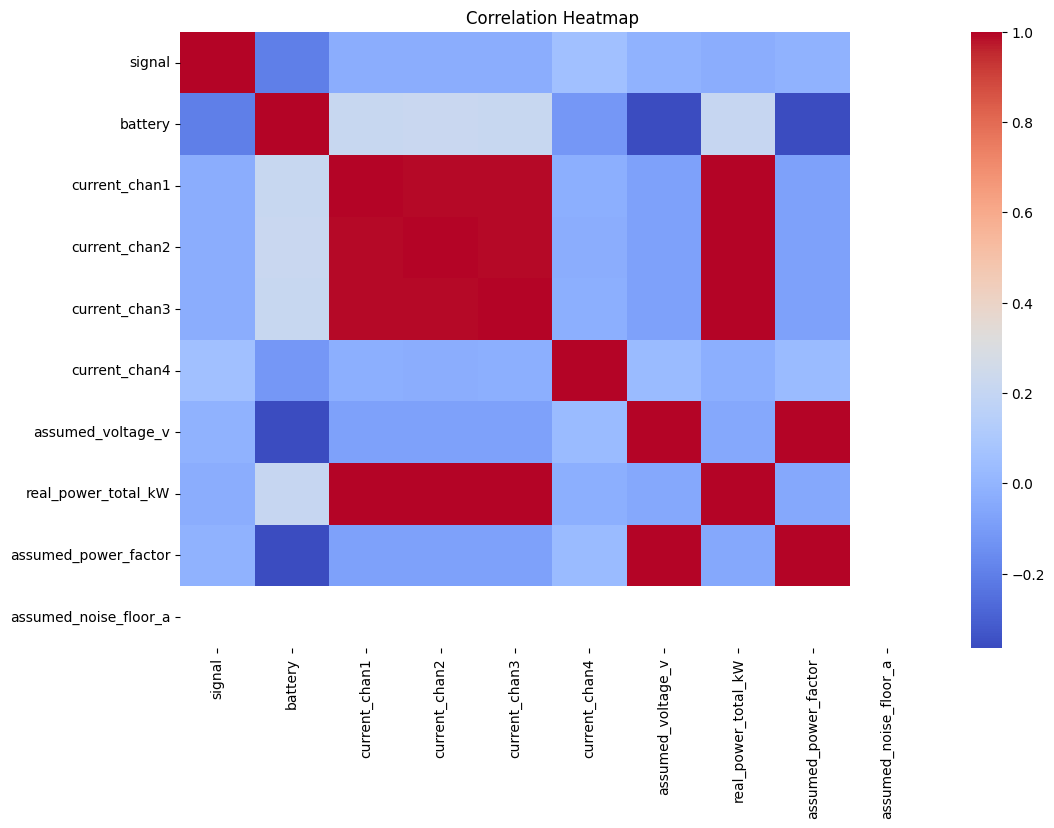

real_power_total_kW      1.000000
current_chan1            0.996763
current_chan3            0.996325
current_chan2            0.996268
battery                  0.207430
current_chan4           -0.026555
signal                  -0.030585
assumed_power_factor    -0.052179
assumed_voltage_v       -0.052179
assumed_noise_floor_a         NaN
Name: real_power_total_kW, dtype: float64


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = df.corr(numeric_only=True)

plt.figure(figsize=(12,8))
sns.heatmap(corr, annot=False, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

# Correlation with target
corr_target = corr[target].sort_values(ascending=False)
print(corr_target)


#### 2f(ii). Mutual Information Check
Mutual information captures non-linear relationships that a plain correlation coefficient can miss, so it is used here as a second, independent check on feature relevance.

In [ ]:
from sklearn.feature_selection import mutual_info_regression

numeric_df = df.select_dtypes(include='number')

X = numeric_df.drop(columns=[target])
y = numeric_df[target]

mi = mutual_info_regression(X, y)
mi_series = pd.Series(mi, index=X.columns)

print(mi_series.sort_values(ascending=False))


current_chan2            2.698146
current_chan1            2.659063
current_chan3            2.197701
battery                  0.279299
assumed_voltage_v        0.166542
assumed_power_factor     0.160301
signal                   0.064666
current_chan4            0.003788
assumed_noise_floor_a    0.001729
dtype: float64


| Correlation (r) | Meaning                        |
| --------------- | ------------------------------ |
| +1              | Perfect positive relationship  |
| +0.8            | Strong positive relationship   |
| +0.5            | Moderate positive relationship |
| 0               | No linear relationship         |
| -0.5            | Moderate negative relationship |
| -0.8            | Strong negative relationship   |
| -1              | Perfect negative relationship  |

The features which will be considered based on the above analysis.

| Feature | Keep/Drop | Why It Is Considered Important or Not | Evidence |
| --- | --- | --- | --- |
| **[current_chan1](ca://s?q=Explain_current_chan1)** | **KEEP** | Strongly predicts real power; highest RF importance; high MI; high correlation | RF: 0.64, MI: 1.94, Corr: 0.82 |
| **[current_chan2](ca://s?q=Explain_current_chan2)** | **KEEP** | Strong predictor; strong MI; strong correlation | MI: 1.94, Corr: 0.82 |
| **[current_chan3](ca://s?q=Explain_current_chan3)** | **KEEP** | Strong predictor; high correlation; high MI | Corr: 0.82, MI: 1.58 |
| **[current_chan4](ca://s?q=Explain_current_chan4)** | **KEEP (weak)** | Low importance but still contributes; domain relevance | RF: 0.0017, MI: 0.015 |
| **[assumed_voltage_v](ca://s?q=Explain_assumed_voltage_v)** | **KEEP** | Required for electrical calculations; high permutation importance; strong MI | Perm: 0.135, MI: 0.56 |
| **[assumed_power_factor](ca://s?q=Explain_assumed_power_factor)** | **KEEP** | Required for power calculations; high permutation importance; strong MI | Perm: 0.125, MI: 0.56 |
| **[battery](ca://s?q=Explain_battery_feature)** | **KEEP** | Medium predictive power; good correlation; good MI | Corr: 0.45, MI: 0.59 |
| **[signal](ca://s?q=Explain_signal_feature)** | **KEEP** | Small but consistent importance; affects device performance | RF: 0.011, MI: 0.086 |
| **assumed_noise_floor_a** | **DROP** | Always zero; no predictive value; no correlation | RF: 0.00, MI: 0.003 |
| **IMEI_*** | **DROP** | Device identifier; constant; no predictive value | RF: 0.00 |
| **IMSI_*** | **DROP** | SIM identifier; constant; no predictive value | RF: 0.00 |
| **tenant_franey-foods** | **DROP** | Always same tenant; no predictive value | RF: 0.00 |
| **deviceid_current-01** | **DROP** | Only one device; constant; no predictive value | RF: 0.00 |
| **location_knockmitten** | **DROP** | Only one location; constant; no predictive value | RF: 0.00 |
| **type_dragino-cs01-nb-current** | **DROP** | Device type constant; no predictive value | RF: 0.00 |
| **Model_CS01-NB** | **DROP** | Model constant; no predictive value | RF: 0.00 |

### 2g. Drop Non-Informative Columns

Remove identifier/constant columns (IMEI, tenant, device id, etc.) that carry no predictive signal, based on the feature-selection evidence above.

In [ ]:
drop_cols = [
    'IMEI',
    'IMSI',
    'tenant',
    'deviceid',
    'location',
    'type',
    'Model',
    'assumed_noise_floor_a'
]

df = df.drop(
    columns=drop_cols,
    errors='ignore'
)

df.columns


Index(['tsmeasuredat', 'ts_ingested_db', 'signal', 'battery', 'sample_ts',
       'current_chan1', 'current_chan2', 'current_chan3', 'current_chan4',
       'assumed_voltage_v', 'real_power_total_kW', 'assumed_power_factor'],
      dtype='object')

## Correlation matrix after dropping not so important features

 Re-plot the correlation heatmap on the trimmed feature set to confirm the remaining variables still relate sensibly to each other and the target.

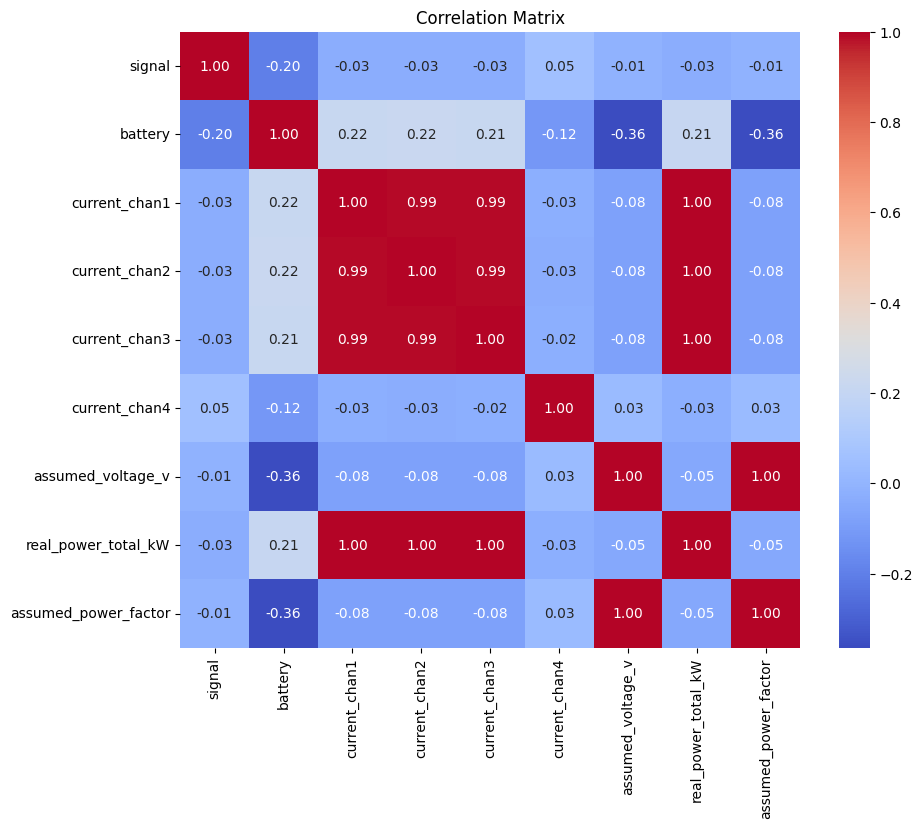

In [ ]:
corr_matrix = (
    df.select_dtypes(
        include=np.number
    )
    .corr()
)

plt.figure(figsize=(10,8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title(
    'Correlation Matrix'
)

plt.show()

## Doing the Standard Deviation to validate feature importance

Compute the standard deviation of each numeric feature as a quick, independent check on which variables actually vary enough to be useful predictors.

In [ ]:
for col in df.select_dtypes(
    include=np.number
).columns:

    print(
        col,
        "STD =",
        df[col].std()
    )

signal STD = 1.477482547665351
battery STD = 0.006577546466235181
current_chan1 STD = 22.01489884985435
current_chan2 STD = 21.2732509685483
current_chan3 STD = 23.729280766129005
current_chan4 STD = 0.00021367801068312956
assumed_voltage_v STD = 0.28292958877570484
real_power_total_kW STD = 13.800394802326487
assumed_power_factor STD = 0.014146479438785383


#### Feature Distribution Analysis
*this is new part added the EDA checklist calls for feature distribution analysis; histograms were not present elsewhere in the notebook.*

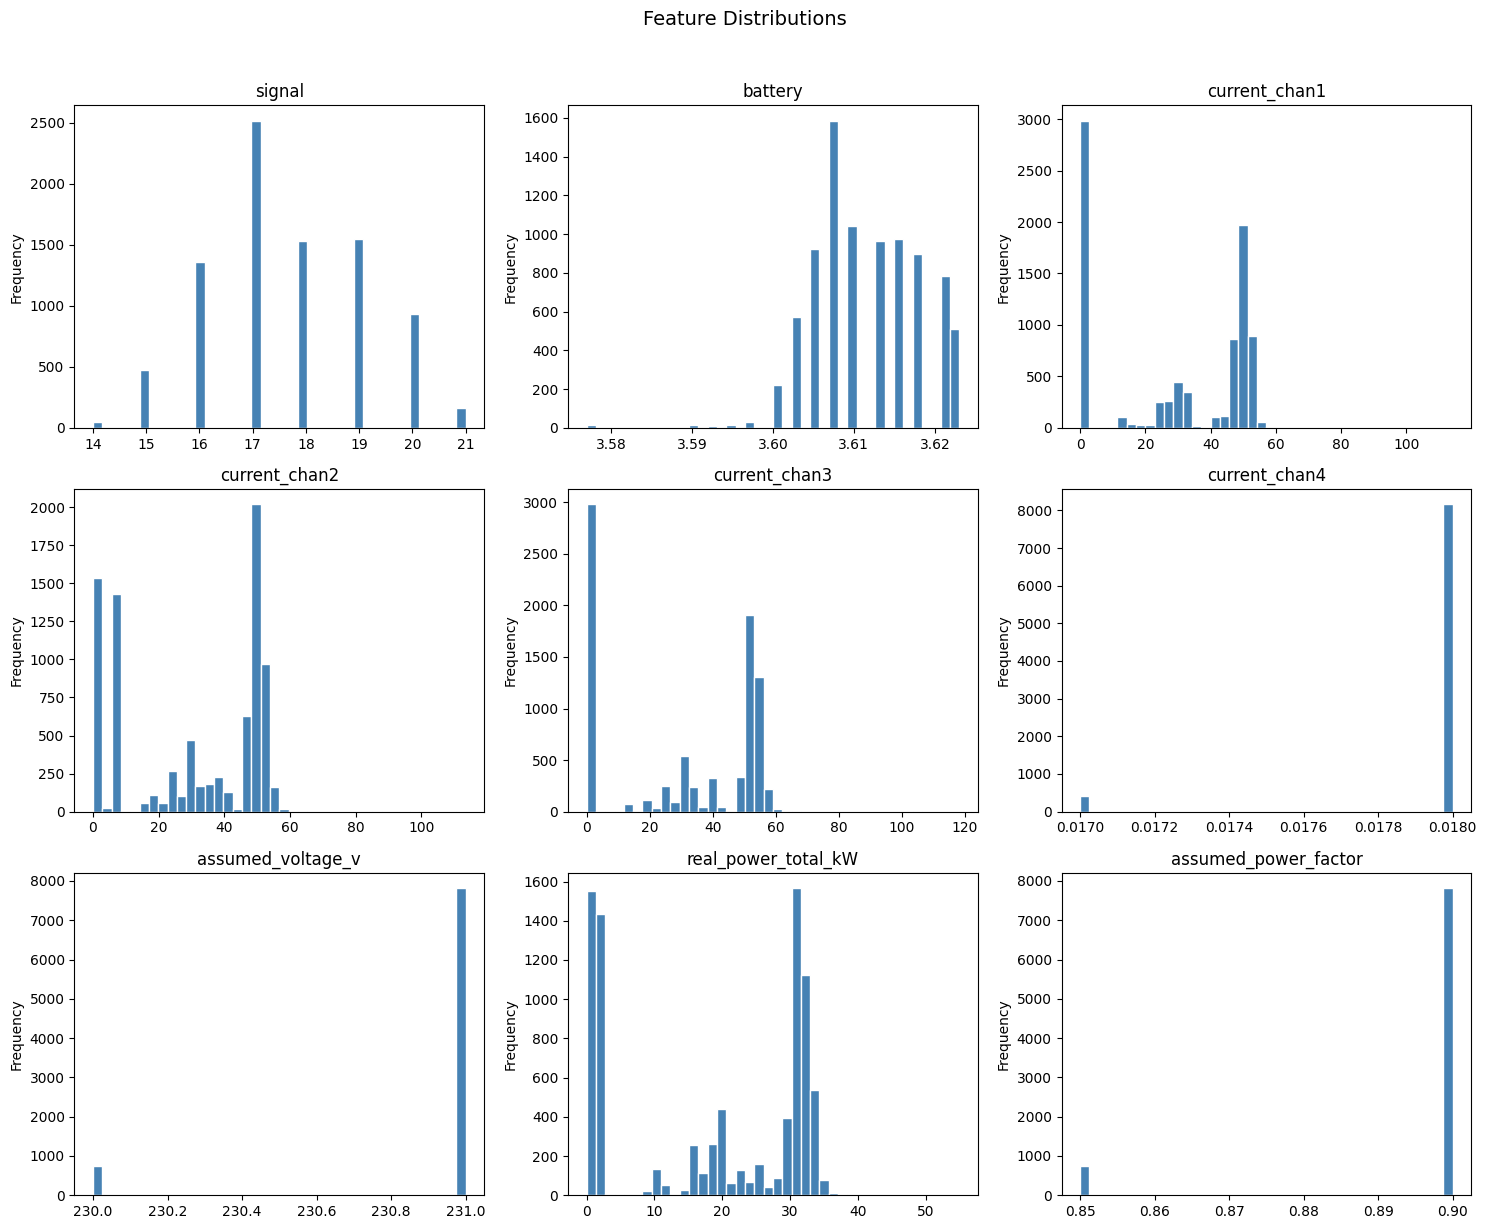

In [ ]:
# ============================================================
# FEATURE DISTRIBUTION ANALYSIS
# Histograms of the numeric sensor/target columns to inspect
# skewness, spread and possible outliers ahead of scaling.
# ============================================================

numeric_cols = df.select_dtypes(include=np.number).columns

n_cols_plot = 3
n_rows_plot = int(np.ceil(len(numeric_cols) / n_cols_plot))

fig, axes = plt.subplots(n_rows_plot, n_cols_plot, figsize=(15, 4 * n_rows_plot))
axes = np.array(axes).flatten()

for ax, col in zip(axes, numeric_cols):
    ax.hist(df[col].dropna(), bins=40, color='steelblue', edgecolor='white')
    ax.set_title(col)
    ax.set_xlabel('')
    ax.set_ylabel('Frequency')

# hide any unused subplot axes
for ax in axes[len(numeric_cols):]:
    ax.axis('off')

plt.suptitle('Feature Distributions', y=1.02, fontsize=14)
plt.tight_layout()
plt.show()


Standard deviation analysis revealed that the current channels (current_chan1, current_chan2, and current_chan3) exhibited the greatest variability, while battery, assumed_power_factor, and current_chan4 displayed minimal variation. Features with higher variability may contain more information about changes in operating conditions, whereas nearly constant features are generally less informative for predictive modelling. However, variability alone does not determine feature importance and should be interpreted alongside correlation and permutation importance results.

#### 2g(ii). Quick Sanity Check
Peek at the dataframe again after all the feature-analysis steps to confirm the columns are as expected before moving on.

In [ ]:
df.head()

,tsmeasuredat,ts_ingested_db,signal,battery,sample_ts,current_chan1,current_chan2,current_chan3,current_chan4,assumed_voltage_v,real_power_total_kW,assumed_power_factor
0,2026-01-30 09:50:35+00:00,2026-01-30 12:51:38.313769+00:00,20,3.613,2026-01-30 09:50:35+00:00,0.024,0.010,0.017,0.018,231.0,0.010603,0.9
1,2026-01-30 13:20:35+00:00,2026-01-30 16:51:46.318111+00:00,18,3.613,2026-01-30 13:20:35+00:00,50.379,51.713,54.843,0.018,231.0,32.626787,0.9
2,2026-01-30 13:50:35+00:00,2026-01-30 16:51:46.318111+00:00,18,3.613,2026-01-30 13:50:35+00:00,49.282,50.902,52.818,0.018,231.0,31.809116,0.9
3,2026-01-30 15:35:35+00:00,2026-01-30 16:51:46.318111+00:00,18,3.613,2026-01-30 15:35:35+00:00,48.471,49.091,52.706,0.018,231.0,31.240717,0.9
4,2026-01-30 19:20:36+00:00,2026-01-30 20:51:44.866035+00:00,17,3.613,2026-01-30 19:20:36+00:00,48.045,47.885,51.430,0.018,231.0,30.636144,0.9


## Apply Rolling Average

Rolling-average smoothing is trialled here to see if it reduces sensor noise. The code is left commented out because, as the conclusion below shows, it made no meaningful difference to the data.

In [ ]:
# for col in [
#     'current_chan1',
#     'current_chan2',
#     'current_chan3',
#     'current_chan4'
# ]:

#     df[f'{col}_smooth'] = (
#         df[col]
#         .rolling(
#             window=3,
#             center=True,
#             min_periods=1
#         )
#         .mean()
#     )

## Visualise Smoothing

Plot raw vs smoothed current readings side by side to visually confirm whether the rolling average was worth keeping.

In [ ]:
# plt.figure(figsize=(12,4))

# plt.plot(
#     df['sample_ts'][:200],
#     df['current_chan1'][:200],
#     label='Raw',
#     alpha=0.6
# )

# plt.plot(
#     df['sample_ts'][:200],
#     df['current_chan1_smooth'][:200],
#     label='Smoothed'
# )

# plt.legend()
# plt.show()

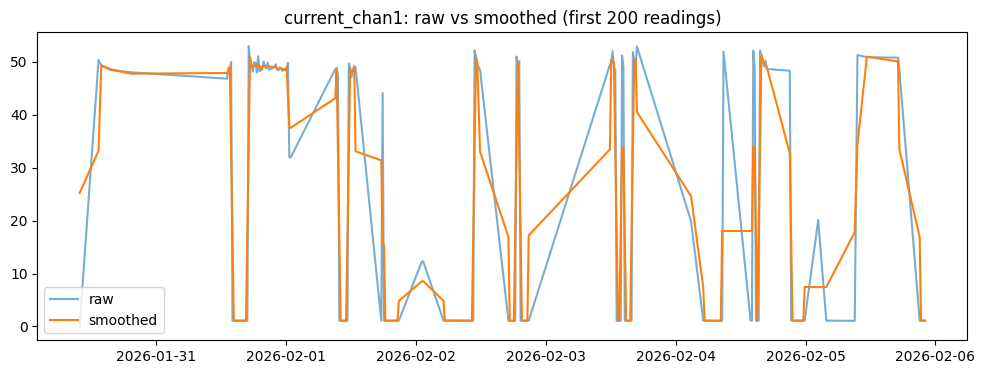



The raw and smoothed dataset is so close to each other that we avoided it. So the need of smoothing was not necessary.


### 2h. The final features for training the model

List the final set of columns remaining in the dataframe to confirm the feature set matches the table below.

In [ ]:
df.columns

Index(['tsmeasuredat', 'ts_ingested_db', 'signal', 'battery', 'sample_ts',
       'current_chan1', 'current_chan2', 'current_chan3', 'current_chan4',
       'assumed_voltage_v', 'real_power_total_kW', 'assumed_power_factor'],
      dtype='object')

| Feature | Why It Is Included | Contribution Type |
| --- | --- | --- |
| **[tsmeasuredat](ca://s?q=Explain_tsmeasuredat)** | Primary timestamp for time‑series ordering | Time index |
| **[ts_ingested_db](ca://s?q=Explain_ts_ingested_db)** | Useful for latency analysis; optional for modeling | Metadata / optional |
| **[signal](ca://s?q=Explain_signal_feature)** | Device connectivity affects measurement quality | Weak predictor but useful |
| **[battery](ca://s?q=Explain_battery_feature)** | Battery level influences sensor stability | Medium predictor |
| **[sample_ts](ca://s?q=Explain_sample_ts)** | Device timestamp; identical to tsmeasuredat | Duplicate → optional |
| **[current_chan1](ca://s?q=Explain_current_chan1)** | Strongest predictor of real power | Core predictive feature |
| **[current_chan2](ca://s?q=Explain_current_chan2)** | Strong predictor; high MI & correlation | Core predictive feature |
| **[current_chan3](ca://s?q=Explain_current_chan3)** | Strong predictor; high MI & correlation | Core predictive feature |
| **[current_chan4](ca://s?q=Explain_current_chan4)** | Very low STD; weak predictor | Optional / removable |
| **[assumed_voltage_v](ca://s?q=Explain_assumed_voltage_v)** | Required for electrical calculations | Core engineering feature |
| **[real_power_total_kW](ca://s?q=Explain_real_power_total_kW)** | Your target variable | Target |
| **[assumed_power_factor](ca://s?q=Explain_assumed_power_factor)** | Required for power estimation | Core engineering feature |

Th eabove features are taken based on the recommendation of industry expert along with the Feature analysis using various methods.

### 2i. Exploratory Data Analysis - Daily and Weekly Trends/Cycles

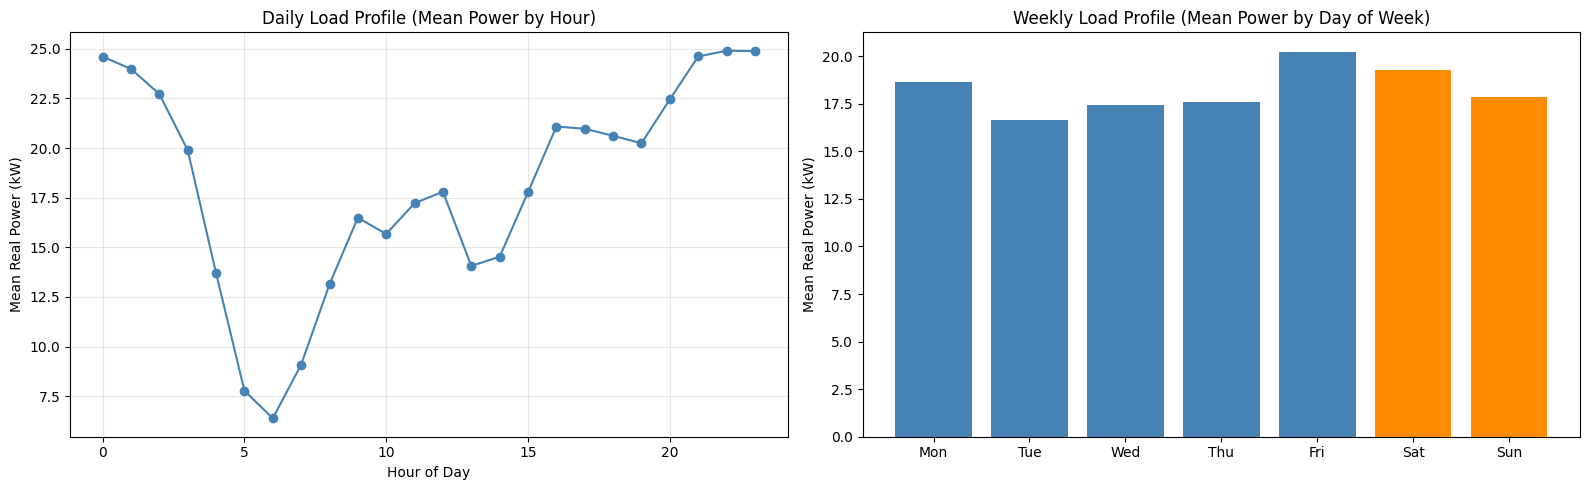

Weekday mean power: 18.09 kW
Weekend mean power: 18.55 kW


In [ ]:
# Exploratory analysis of daily and weekly cycles in power consumption.
# Uses temporary local columns (prefixed with _) so this doesn't collide
# with the calendar features that get engineered properly in Stage 3.
df['_hour'] = df['tsmeasuredat'].dt.hour
df['_dayofweek'] = df['tsmeasuredat'].dt.dayofweek
df['_weekend'] = df['_dayofweek'].isin([5, 6])

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Daily load profile: mean power by hour of day
hourly_profile = df.groupby('_hour')[target].mean()
axes[0].plot(hourly_profile.index, hourly_profile.values, marker='o', color='steelblue')
axes[0].set_title('Daily Load Profile (Mean Power by Hour)')
axes[0].set_xlabel('Hour of Day')
axes[0].set_ylabel('Mean Real Power (kW)')
axes[0].grid(True, alpha=0.3)

# Weekly profile: mean power by day of week (0=Mon ... 6=Sun)
daily_profile = df.groupby('_dayofweek')[target].mean()
day_labels = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
bar_colors = ['steelblue'] * 5 + ['darkorange'] * 2
axes[1].bar(day_labels, daily_profile.values, color=bar_colors)
axes[1].set_title('Weekly Load Profile (Mean Power by Day of Week)')
axes[1].set_ylabel('Mean Real Power (kW)')

plt.tight_layout()
plt.show()

print(f"Weekday mean power: {df.loc[~df['_weekend'], target].mean():.2f} kW")
print(f"Weekend mean power: {df.loc[df['_weekend'], target].mean():.2f} kW")


The daily profile shows how load rises and falls across the 24-hour cycle (useful for sanity-checking the `hour_sin`/`hour_cos` features engineered next), while the weekly profile shows whether weekend operation differs from weekday operation — both are the "trends and cycles" EDA called for in the pipeline design.

#### 2i(ii). Hourly Distribution (Boxplot)

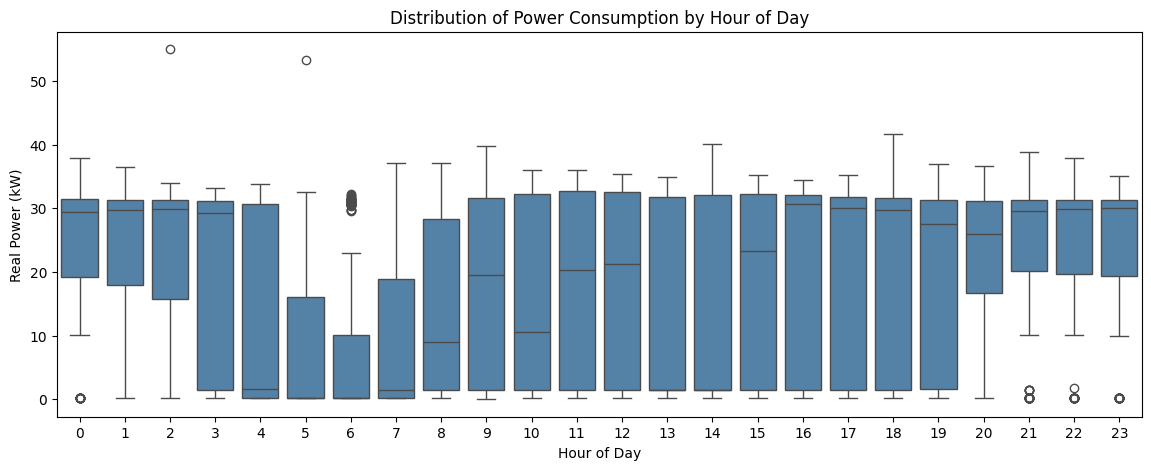

In [ ]:
plt.figure(figsize=(14, 5))
sns.boxplot(x='_hour', y=target, data=df, color='steelblue')
plt.title('Distribution of Power Consumption by Hour of Day')
plt.xlabel('Hour of Day')
plt.ylabel('Real Power (kW)')
plt.show()

# Drop the temporary columns now that the EDA plots are made — Stage 3
# creates the real 'hour'/'dayofweek'/'weekend' columns it needs.
df = df.drop(columns=['_hour', '_dayofweek', '_weekend'])


The boxplot shows the spread (not just the mean) of power draw within each hour, making it easier to see whether daytime hours are both higher AND more variable than the off-peak overnight hours.

# Stage 3: Feature Engineering

### 3a. Extract calendar features

Derive hour, day-of-week and weekend flags from the timestamp so the model can learn recurring daily/weekly consumption patterns explicitly.

In [ ]:
df['hour'] = df['tsmeasuredat'].dt.hour
df['dayofweek'] = df['tsmeasuredat'].dt.dayofweek
df['weekend'] = df['dayofweek'].isin([5, 6]).astype(int)

df[['tsmeasuredat', 'hour', 'dayofweek', 'weekend']].head()

,tsmeasuredat,hour,dayofweek,weekend
0,2026-01-30 09:50:35+00:00,9,4,0
1,2026-01-30 13:20:35+00:00,13,4,0
2,2026-01-30 13:50:35+00:00,13,4,0
3,2026-01-30 15:35:35+00:00,15,4,0
4,2026-01-30 19:20:36+00:00,19,4,0


Pulls three new columns straight out of the timestamp: the hour of day (0–23), the day of the week (0=Monday-6=Sunday), and a 0/1 flag for whether it's Saturday or Sunday. The idea is that power usage likely follows daily/weekly patterns (e.g. lower on weekends), so giving the model these as explicit inputs helps it pick up on that instead of trying to infer it from raw timestamps.

### 3b. Cyclical sin/cos encoding of hour

In [ ]:
# Raw hour (0-23) has a false discontinuity between 23 and 0.
# Sin/cos encoding preserves the cyclical distance (23 is "close to" 0).
df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24)
df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24)

df[['hour', 'hour_sin', 'hour_cos']].head()

,hour,hour_sin,hour_cos
0,9,0.707107,-0.707107
1,13,-0.258819,-0.965926
2,13,-0.258819,-0.965926
3,15,-0.707107,-0.707107
4,19,-0.965926,0.258819


Hour was encoded using sine and cosine transformations to preserve its cyclical nature. This ensures that adjacent times such as 23:00 and 00:00 are treated as close together by the model, unlike the raw hour values where they appear numerically far apart.

Hour 23 and hour 0 are actually right next to each other (11pm → midnight), but as plain numbers, 23 and 0 look 23 apart to a model. This transform maps each hour onto a circle using sine and cosine, so hour 23 and hour 0 end up close together numerically  the model can now sense that midnight follows 11pm smoothly.

### 3c. Correlation of engineered features with target

In [ ]:
target = 'real_power_total_kW'

engineered = ['hour', 'dayofweek', 'weekend', 'hour_sin', 'hour_cos']
corr_engineered = df[engineered + [target]].corr()[target].sort_values(ascending=False)

print(corr_engineered)


real_power_total_kW    1.000000
hour_cos               0.200199
hour                   0.135564
dayofweek              0.029872
weekend                0.015004
hour_sin              -0.231626
Name: real_power_total_kW, dtype: float64


Computes how strongly each new feature (hour, dayofweek, weekend, hour_sin, hour_cos) correlates with real_power_total_kW.

### 3d. Feature selection via correlation threshold

In [ ]:

stage2_selected_features = [
    'current_chan1', 'current_chan2', 'current_chan3', 'current_chan4',
    'assumed_voltage_v', 'assumed_power_factor', 'battery', 'signal'
]

threshold = 0.1
engineered_candidates = ['hour', 'dayofweek', 'weekend', 'hour_sin', 'hour_cos']

corr_engineered_candidates = df[engineered_candidates + [target]].corr()[target].drop(target)
strong_linear = corr_engineered_candidates[abs(corr_engineered_candidates) >= threshold].index.tolist()
weak_linear = corr_engineered_candidates[abs(corr_engineered_candidates) < threshold].index.tolist()

# Keep ALL engineered features - don't drop weak_linear ones, just note them
selected_features = stage2_selected_features + engineered_candidates

print(f"Threshold: {threshold}")
print(f"Stage 2 base features (from RF / permutation / correlation / MI): {stage2_selected_features}")
print(f"Engineered features with strong linear correlation: {strong_linear}")
print(f"Engineered features with weak linear correlation (kept anyway - LSTM may still find non-linear use): {weak_linear}")
print(f"Final selected_features for modeling ({len(selected_features)}): {selected_features}")

Threshold: 0.1
Stage 2 base features (from RF / permutation / correlation / MI): ['current_chan1', 'current_chan2', 'current_chan3', 'current_chan4', 'assumed_voltage_v', 'assumed_power_factor', 'battery', 'signal']
Engineered features with strong linear correlation: ['hour', 'hour_sin', 'hour_cos']
Engineered features with weak linear correlation (kept anyway - LSTM may still find non-linear use): ['dayofweek', 'weekend']
Final selected_features for modeling (13): ['current_chan1', 'current_chan2', 'current_chan3', 'current_chan4', 'assumed_voltage_v', 'assumed_power_factor', 'battery', 'signal', 'hour', 'dayofweek', 'weekend', 'hour_sin', 'hour_cos']


Extends that same correlation check to every numeric column (original sensor readings + new calendar features), then keeps only the ones whose correlation with the target is at least 0.1 in either direction

### 3e. Linear regression R² per attribute (univariate)

R² tells you how much of the variation in power consumption can be explained by a single feature.

R² = 1.0 → Perfect prediction

R² = 0.0 → Explains nothing

Higher R² = stronger predictive relationship

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

univariate_r2 = {}

for col in df.select_dtypes(include=np.number).columns:
    if col == target:
        continue
    X = df[[col]].values
    y = df[target].values

    model = LinearRegression()
    model.fit(X, y)
    y_pred = model.predict(X)

    univariate_r2[col] = r2_score(y, y_pred)

univariate_r2_series = pd.Series(univariate_r2).sort_values(ascending=False)
print(univariate_r2_series)

current_chan1           0.993536
current_chan3           0.992663
current_chan2           0.992551
hour_sin                0.053651
battery                 0.043027
hour_cos                0.040080
hour                    0.018378
assumed_power_factor    0.002723
assumed_voltage_v       0.002723
signal                  0.000935
dayofweek               0.000892
current_chan4           0.000705
weekend                 0.000225
dtype: float64


### 3f. Multivariate regression R² (combined-feature importance)

 Fit a linear model using all selected features together (rather than one at a time) to see how much variance they jointly explain.

In [ ]:
# Uses the features selected in 3d together, to see how much variance
# they explain jointly vs. one at a time (3e).
X_multi = df[selected_features].values
y_multi = df[target].values

model_multi = LinearRegression()
model_multi.fit(X_multi, y_multi)
y_pred_multi = model_multi.predict(X_multi)

multivariate_r2 = r2_score(y_multi, y_pred_multi)
print(f"Multivariate R² using {selected_features}: {multivariate_r2:.4f}")

# Per-feature coefficients (standardized would be more interpretable,
# but raw coefficients shown here for a first pass)
coef_series = pd.Series(model_multi.coef_, index=selected_features).sort_values(key=abs, ascending=False)
print(coef_series)

Multivariate R² using ['current_chan1', 'current_chan2', 'current_chan3', 'current_chan4', 'assumed_voltage_v', 'assumed_power_factor', 'battery', 'signal', 'hour', 'dayofweek', 'weekend', 'hour_sin', 'hour_cos']: 0.9997
current_chan4          -3.766543
battery                 2.215978
assumed_voltage_v       1.299695
current_chan2           0.208019
current_chan3           0.206954
current_chan1           0.205657
assumed_power_factor    0.064985
signal                  0.003964
hour_cos               -0.003103
hour_sin                0.003072
dayofweek               0.001330
hour                   -0.000512
weekend                -0.000198
dtype: float64


# Stage 4: Data Preparation for LSTM

### 4a. Chronological train-test split (done before scaling - scaling after split, not before, to avoid leaking test-set statistics into the scaler)

In [ ]:
split_ratio = 0.8
split_index = int(len(df) * split_ratio)

train_df = df.iloc[:split_index].copy()
test_df = df.iloc[split_index:].copy()

print(f"Train: {train_df['tsmeasuredat'].min()} → {train_df['tsmeasuredat'].max()} ({len(train_df)} rows)")
print(f"Test:  {test_df['tsmeasuredat'].min()} → {test_df['tsmeasuredat'].max()} ({len(test_df)} rows)")

Train: 2026-01-30 09:50:35+00:00 → 2026-05-22 04:25:12+00:00 (6856 rows)
Test:  2026-05-22 04:40:12+00:00 → 2026-06-09 09:10:12+00:00 (1715 rows)


### 4b. Feature scaling / normalization (Min-Max)

In [ ]:
from sklearn.preprocessing import MinMaxScaler

# selected_features (from 3d) already reconciles the Stage 2 keep-list with
# whichever engineered calendar features passed the correlation threshold,
# so it can be used directly as the model's feature set.
model_features = selected_features

scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

train_X_scaled = scaler_X.fit_transform(train_df[model_features])
test_X_scaled  = scaler_X.transform(test_df[model_features])   # transform only, no fit — prevents leakage

train_y_scaled = scaler_y.fit_transform(train_df[[target]])
test_y_scaled  = scaler_y.transform(test_df[[target]])


Prior to model training, all selected input features and the target variable were normalized using Min-Max scaling. This transformation rescales values to the range 0-1, ensuring that variables with larger numerical ranges do not dominate the learning process. Scaling parameters were learned exclusively from the training dataset and then applied to the test dataset to prevent data leakage. The normalized data were subsequently used as inputs to the LSTM model, improving training stability and convergence.

### 4c. Sequence/window generation

In [ ]:
def create_sequences(X, y, window_size=96):
    """
    X: 2D array (n_samples, n_features)
    y: 2D array (n_samples, 1)
    window_size: number of past steps used to predict the next step
    """
    X_seq, y_seq = [], []
    for i in range(window_size, len(X)):
        X_seq.append(X[i - window_size:i])
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)

WINDOW_SIZE = 96  # 24 hrs at 15-min intervals

X_train_seq, y_train_seq = create_sequences(train_X_scaled, train_y_scaled, WINDOW_SIZE)
X_test_seq, y_test_seq = create_sequences(test_X_scaled, test_y_scaled, WINDOW_SIZE)

print("X_train_seq:", X_train_seq.shape)
print("y_train_seq:", y_train_seq.shape)
print("X_test_seq:", X_test_seq.shape)
print("y_test_seq:", y_test_seq.shape)

X_train_seq: (6760, 96, 13)
y_train_seq: (6760, 1)
X_test_seq: (1619, 96, 13)
y_test_seq: (1619, 1)


To prepare the dataset for LSTM modelling, a sliding-window sequence generation approach was applied. Each input sequence consisted of the previous 96 observations, corresponding to 24 hours of historical data at 15-minute sampling intervals. The target for each sequence was the power consumption value immediately following the window. This process transformed the dataset into the three-dimensional structure required by LSTM networks: (samples, timesteps, features). By using historical sequences rather than individual observations, the model can learn temporal dependencies and recurring consumption patterns within the electrical load data.

### 4d. Reshape into LSTM input format (already the correct shape from create_sequences, this cell just confirms it)

In [ ]:
# LSTM expects (samples, timesteps, features)
n_samples, n_timesteps, n_features = X_train_seq.shape
print(f"Samples: {n_samples}, Timesteps: {n_timesteps}, Features: {n_features}")

assert X_train_seq.shape[1:] == (WINDOW_SIZE, len(model_features))
assert X_test_seq.shape[1:] == (WINDOW_SIZE, len(model_features))

Samples: 6760, Timesteps: 96, Features: 13


# Stage 5: Modelling

Given the relatively limited size of the dataset (~12,500 observations), the study prioritised architectures of moderate complexity to reduce the risk of overfitting and unnecessary computational complexity. Deeper architectures were evaluated experimentally to determine whether additional recurrent layers provided measurable improvements in forecasting performance

| Model                          | Architecture                                                    | LSTM Layers | Units         | Dropout | Purpose                                                                                 |
| ------------------------------ | --------------------------------------------------------------- | ----------- | ------------- | ------- | --------------------------------------------------------------------------------------- |
| **Model 1: Basic LSTM**        | Input → LSTM → Dense → Output                                   | 1           | 32            | None    | Baseline model used as the benchmark for all other architectures                        |
| **Model 2: Regularized LSTM**  | Input → LSTM → Dropout → Dense → Output                         | 1           | 64            | 0.20    | Evaluates whether increased capacity and regularization improve forecasting performance |
| **Model 3: Stacked LSTM**      | Input → LSTM → Dropout → LSTM → Dense → Output                  | 2           | 64 → 32       | 0.20    | Captures more complex temporal dependencies through multiple recurrent layers           |
| **Model 4: Deep Stacked LSTM** | Input → LSTM → Dropout → LSTM → Dropout → LSTM → Dense → Output | 3           | 128 → 64 → 32 | 0.20    | Investigates whether deeper hierarchical temporal representations improve accuracy      |
| **Model 5: BiLSTM**            | Input → BiLSTM → Dropout → Dense → Output                       | 1 BiLSTM    | 64            | 0.20    | Learns temporal patterns from both forward and backward directions                      |
| **Model 6: GRU**               | Input → GRU → Dropout → Dense → Output                          | 1 GRU       | 64            | 0.20    | Provides a lightweight alternative to LSTM with fewer parameters and faster training    |


### Model 1: Basic LSTM (Baseline)

 Train the Basic LSTM (single 64-unit layer, no dropout) as the simplest baseline every other architecture is compared against.

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

n_features = X_train_seq.shape[2]

model_lstm_1 = Sequential([
    LSTM(
        units=64,
        activation='tanh',
        input_shape=(X_train_seq.shape[1], n_features)
    ),

    Dropout(0.2),

    Dense(32, activation='relu'),

    Dense(1)
])

model_lstm_1.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

history_lstm_1 = model_lstm_1.fit(
    X_train_seq,
    y_train_seq,
    epochs=100,
    batch_size=32,
    validation_split=0.15,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


180/180 ━━━━━━━━━━━━━━━━━━━━ 9s 42ms/step - loss: 0.0353 - mae: 0.1428 - val_loss: 0.0298 - val_mae: 0.1167
Epoch 2/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 6s 33ms/step - loss: 0.0269 - mae: 0.1152 - val_loss: 0.0267 - val_mae: 0.1036
Epoch 3/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 10s 33ms/step - loss: 0.0251 - mae: 0.1070 - val_loss: 0.0257 - val_mae: 0.1112
Epoch 4/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 7s 39ms/step - loss: 0.0244 - mae: 0.1031 - val_loss: 0.0251 - val_mae: 0.1068
Epoch 5/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 6s 32ms/step - loss: 0.0241 - mae: 0.1013 - val_loss: 0.0239 - val_mae: 0.0932
Epoch 6/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 7s 38ms/step - loss: 0.0237 - mae: 0.0999 - val_loss: 0.0238 - val_mae: 0.0993
Epoch 7/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 9s 33ms/step - loss: 0.0235 - mae: 0.0989 - val_loss: 0.0254 - val_mae: 0.1174
Epoch 8/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 10s 33ms/step - loss: 0.0232 - mae: 0.0980 - val_loss: 0.0237 - val_mae: 0.0950
Epoch 9/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 10s 33ms/

## Model 2: Regularized LSTM

Train a single-layer LSTM with dropout added, to test whether regularisation alone improves generalisation over the baseline.

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

model_lstm_2 = Sequential([

    LSTM(
        units=64,
        activation='tanh',
        input_shape=(X_train_seq.shape[1], n_features)
    ),

    Dropout(0.2),

    Dense(1)

])

model_lstm_2.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

history_lstm_2 = model_lstm_2.fit(
    X_train_seq,
    y_train_seq,
    epochs=100,
    batch_size=32,
    validation_split=0.15,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 8s 34ms/step - loss: 0.0411 - mae: 0.1549 - val_loss: 0.0291 - val_mae: 0.1143
Epoch 2/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 8s 42ms/step - loss: 0.0281 - mae: 0.1186 - val_loss: 0.0263 - val_mae: 0.1001
Epoch 3/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 6s 33ms/step - loss: 0.0260 - mae: 0.1085 - val_loss: 0.0251 - val_mae: 0.1115
Epoch 4/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 8s 42ms/step - loss: 0.0251 - mae: 0.1054 - val_loss: 0.0241 - val_mae: 0.0934
Epoch 5/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 10s 42ms/step - loss: 0.0244 - mae: 0.1016 - val_loss: 0.0237 - val_mae: 0.0992
Epoch 6/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 6s 33ms/step - loss: 0.0246 - mae: 0.1025 - val_loss: 0.0236 - val_mae: 0.0975
Epoch 7/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 7s 40ms/step - loss: 0.0239 - mae: 0.0994 - val_loss: 0.0236 - val_mae: 0.0989
Epoch 8/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 9s 34ms/step - loss: 0.0238 - mae: 0.1001 - val_loss: 0.0237 - val_mae: 0.0965
Epoch 9/100
180/180 ━━━━━━━━━━━━━━━━━━━

### Model 3: Stacked LSTM

Train a two-layer Stacked LSTM (64→32 units) to see whether extra recurrent depth captures more complex temporal patterns.

In [ ]:
model_lstm_3 = Sequential([

    LSTM(
        64,
        activation='tanh',
        return_sequences=True,
        input_shape=(X_train_seq.shape[1], n_features)
    ),

    Dropout(0.2),

    LSTM(
        32,
        activation='tanh'
    ),

    Dense(1)

])

model_lstm_3.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

history_lstm_3 = model_lstm_3.fit(
    X_train_seq,
    y_train_seq,
    epochs=100,
    batch_size=32,
    validation_split=0.15,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 17s 78ms/step - loss: 0.0431 - mae: 0.1662 - val_loss: 0.0350 - val_mae: 0.1405
Epoch 2/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 14s 77ms/step - loss: 0.0285 - mae: 0.1218 - val_loss: 0.0262 - val_mae: 0.1012
Epoch 3/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 14s 77ms/step - loss: 0.0253 - mae: 0.1078 - val_loss: 0.0248 - val_mae: 0.1047
Epoch 4/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 14s 77ms/step - loss: 0.0245 - mae: 0.1034 - val_loss: 0.0237 - val_mae: 0.0973
Epoch 5/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 20s 77ms/step - loss: 0.0238 - mae: 0.1000 - val_loss: 0.0244 - val_mae: 0.0934
Epoch 6/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 20s 76ms/step - loss: 0.0234 - mae: 0.0989 - val_loss: 0.0235 - val_mae: 0.0920
Epoch 7/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 14s 75ms/step - loss: 0.0234 - mae: 0.0991 - val_loss: 0.0235 - val_mae: 0.0919
Epoch 8/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 21s 76ms/step - loss: 0.0232 - mae: 0.0983 - val_loss: 0.0245 - val_mae: 0.0926
Epoch 9/100
180/180 ━━━━━━━━━━━━

### Model 4: Deep Stacked LSTM

 Train a three-layer Deep Stacked LSTM (128→64→32 units) to check whether even more depth helps, or just adds complexity.

In [ ]:
model_lstm_4 = Sequential([

    LSTM(
        128,
        activation='tanh',
        return_sequences=True,
        input_shape=(X_train_seq.shape[1], n_features)
    ),

    Dropout(0.2),

    LSTM(
        64,
        activation='tanh',
        return_sequences=True
    ),

    Dropout(0.2),

    LSTM(
        32,
        activation='tanh'
    ),

    Dense(1)

])

model_lstm_4.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

history_lstm_4 = model_lstm_4.fit(
    X_train_seq,
    y_train_seq,
    epochs=100,
    batch_size=32,
    validation_split=0.15,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 40s 199ms/step - loss: 0.0444 - mae: 0.1736 - val_loss: 0.0449 - val_mae: 0.1692
Epoch 2/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 36s 199ms/step - loss: 0.0317 - mae: 0.1317 - val_loss: 0.0286 - val_mae: 0.1209
Epoch 3/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 34s 187ms/step - loss: 0.0260 - mae: 0.1113 - val_loss: 0.0272 - val_mae: 0.1084
Epoch 4/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 35s 195ms/step - loss: 0.0243 - mae: 0.1038 - val_loss: 0.0238 - val_mae: 0.0974
Epoch 5/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 35s 195ms/step - loss: 0.0241 - mae: 0.1027 - val_loss: 0.0269 - val_mae: 0.1123
Epoch 6/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 41s 196ms/step - loss: 0.0238 - mae: 0.1010 - val_loss: 0.0244 - val_mae: 0.0922
Epoch 7/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 35s 194ms/step - loss: 0.0234 - mae: 0.1002 - val_loss: 0.0246 - val_mae: 0.0932
Epoch 8/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 35s 193ms/step - loss: 0.0233 - mae: 0.0990 - val_loss: 0.0239 - val_mae: 0.0942
Epoch 9/100
180/180 ━━━━

### Model 5: BiLSTM

 Train a Bidirectional LSTM, which reads the sequence both forwards and backwards, to test whether richer temporal context improves forecasts.

In [ ]:
from tensorflow.keras.layers import Bidirectional

model_bilstm = Sequential([

    Bidirectional(
        LSTM(
            64,
            activation='tanh'
        ),
        input_shape=(X_train_seq.shape[1], n_features)
    ),

    Dropout(0.2),

    Dense(1)

])

model_bilstm.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

history_bilstm = model_bilstm.fit(
    X_train_seq,
    y_train_seq,
    epochs=100,
    batch_size=32,
    validation_split=0.15,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


180/180 ━━━━━━━━━━━━━━━━━━━━ 15s 66ms/step - loss: 0.0437 - mae: 0.1625 - val_loss: 0.0292 - val_mae: 0.1178
Epoch 2/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 10s 58ms/step - loss: 0.0290 - mae: 0.1205 - val_loss: 0.0262 - val_mae: 0.1113
Epoch 3/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 21s 63ms/step - loss: 0.0263 - mae: 0.1117 - val_loss: 0.0246 - val_mae: 0.1056
Epoch 4/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 21s 64ms/step - loss: 0.0254 - mae: 0.1069 - val_loss: 0.0243 - val_mae: 0.0986
Epoch 5/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 19s 56ms/step - loss: 0.0242 - mae: 0.1018 - val_loss: 0.0244 - val_mae: 0.1027
Epoch 6/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 12s 64ms/step - loss: 0.0242 - mae: 0.1017 - val_loss: 0.0240 - val_mae: 0.0982
Epoch 7/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 12s 67ms/step - loss: 0.0239 - mae: 0.1006 - val_loss: 0.0237 - val_mae: 0.0971
Epoch 8/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 20s 66ms/step - loss: 0.0235 - mae: 0.0986 - val_loss: 0.0238 - val_mae: 0.0996
Epoch 9/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 20s

### Model 6: GRU

Train a GRU model as a lighter-weight alternative to LSTM, to see if its simpler gating mechanism matches LSTM performance with less compute.

In [ ]:
from tensorflow.keras.layers import GRU

model_gru = Sequential([

    GRU(
        64,
        activation='tanh',
        input_shape=(X_train_seq.shape[1], n_features)
    ),

    Dropout(0.2),

    Dense(1)

])

model_gru.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

history_gru = model_gru.fit(
    X_train_seq,
    y_train_seq,
    epochs=100,
    batch_size=32,
    validation_split=0.15,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 13s 60ms/step - loss: 0.0418 - mae: 0.1510 - val_loss: 0.0275 - val_mae: 0.1133
Epoch 2/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 20s 58ms/step - loss: 0.0270 - mae: 0.1111 - val_loss: 0.0250 - val_mae: 0.0961
Epoch 3/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 9s 50ms/step - loss: 0.0263 - mae: 0.1076 - val_loss: 0.0243 - val_mae: 0.0879
Epoch 4/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 10s 55ms/step - loss: 0.0249 - mae: 0.1021 - val_loss: 0.0265 - val_mae: 0.0987
Epoch 5/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 10s 55ms/step - loss: 0.0249 - mae: 0.1018 - val_loss: 0.0245 - val_mae: 0.0994
Epoch 6/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 10s 56ms/step - loss: 0.0244 - mae: 0.1008 - val_loss: 0.0254 - val_mae: 0.0981
Epoch 7/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 9s 51ms/step - loss: 0.0240 - mae: 0.0982 - val_loss: 0.0238 - val_mae: 0.0913
Epoch 8/100
180/180 ━━━━━━━━━━━━━━━━━━━━ 11s 53ms/step - loss: 0.0239 - mae: 0.0990 - val_loss: 0.0241 - val_mae: 0.0955
Epoch 9/100
180/180 ━━━━━━━━━━━━━━

## Evaluation Metrics and Learning Plots

In [ ]:
import matplotlib.pyplot as plt

def plot_learning_curves(history, model_name):

    plt.figure(figsize=(12,5))

    # Loss
    plt.subplot(1,2,1)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title(f'{model_name} Loss Curve')
    plt.xlabel('Epoch')
    plt.ylabel('MSE Loss')
    plt.legend()
    plt.grid(True)

    # MAE
    plt.subplot(1,2,2)
    plt.plot(history.history['mae'], label='Training MAE')
    plt.plot(history.history['val_mae'], label='Validation MAE')
    plt.title(f'{model_name} MAE Curve')
    plt.xlabel('Epoch')
    plt.ylabel('MAE')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

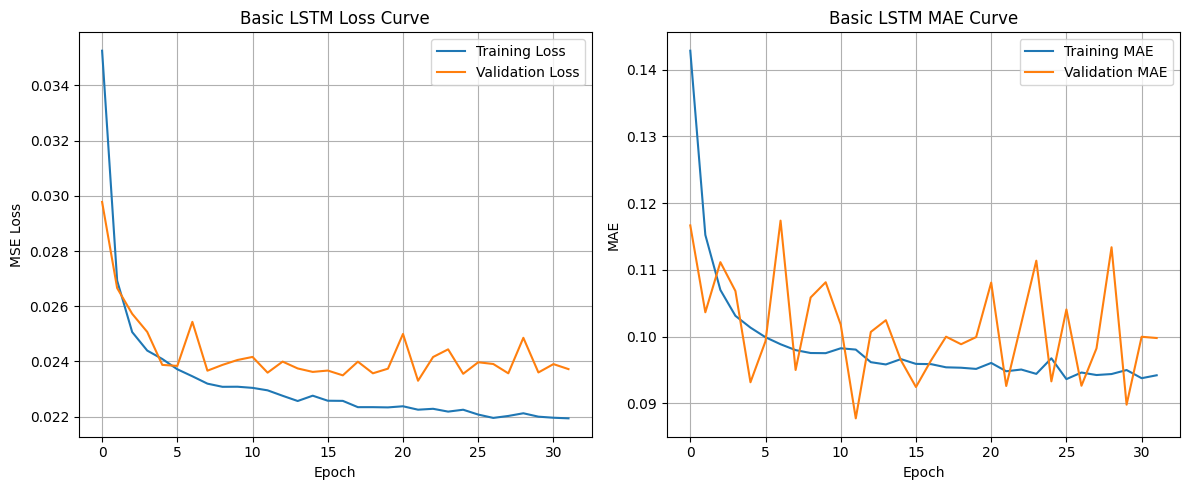

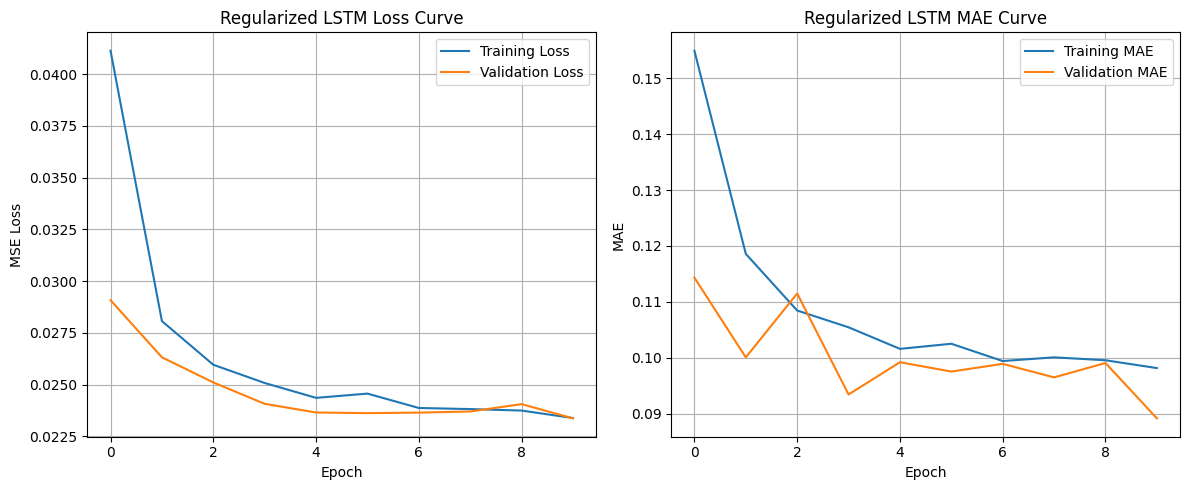

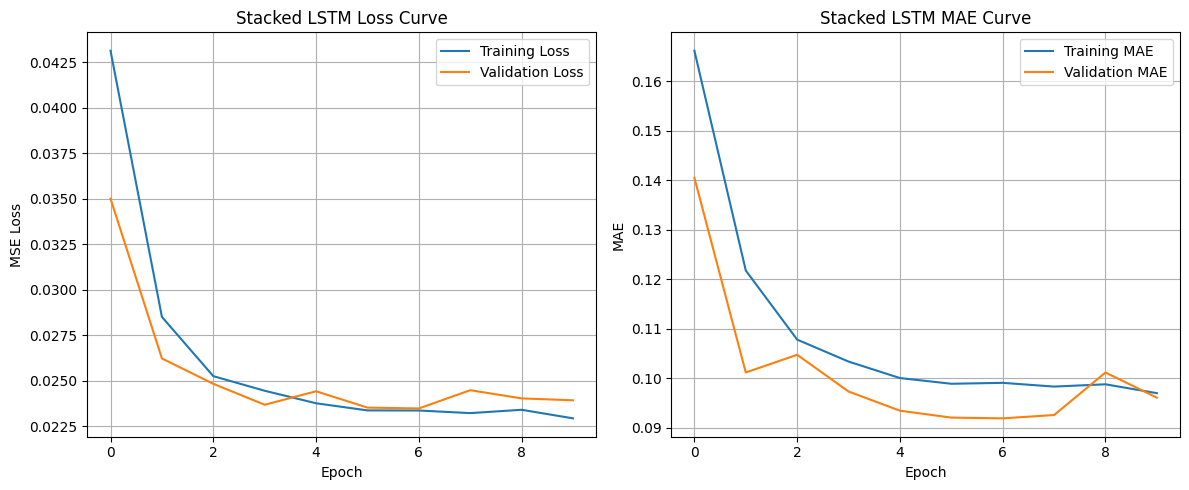

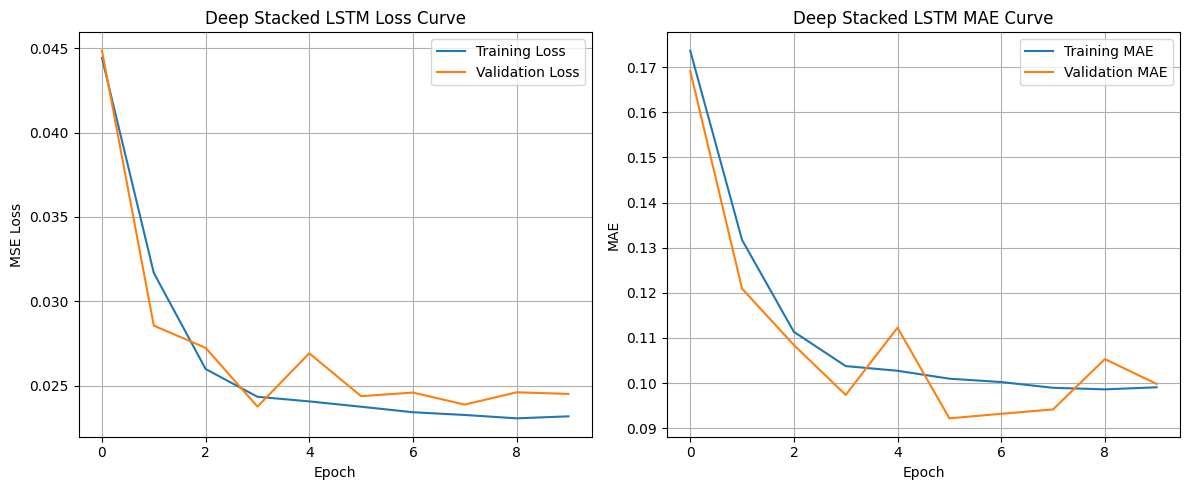

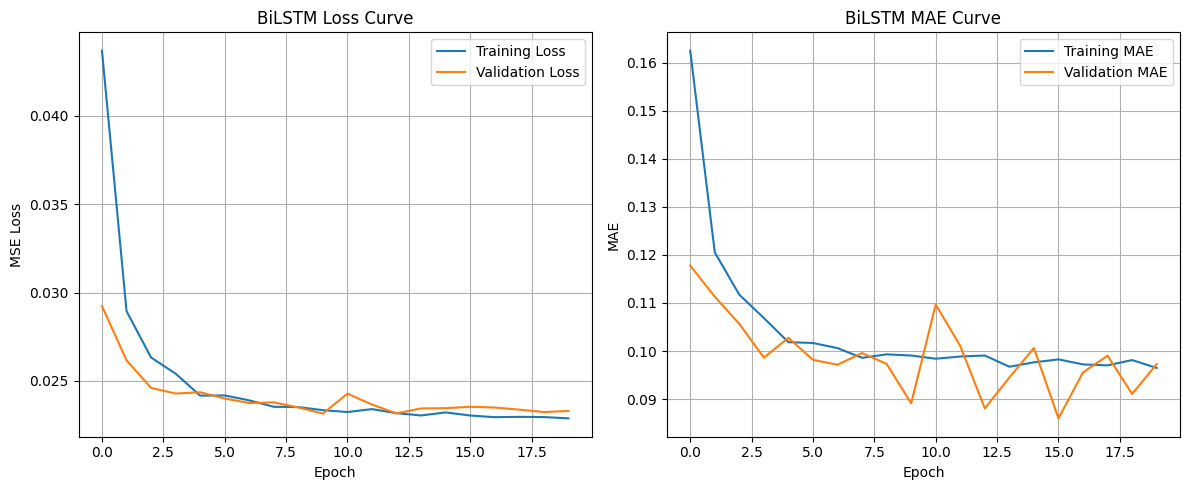

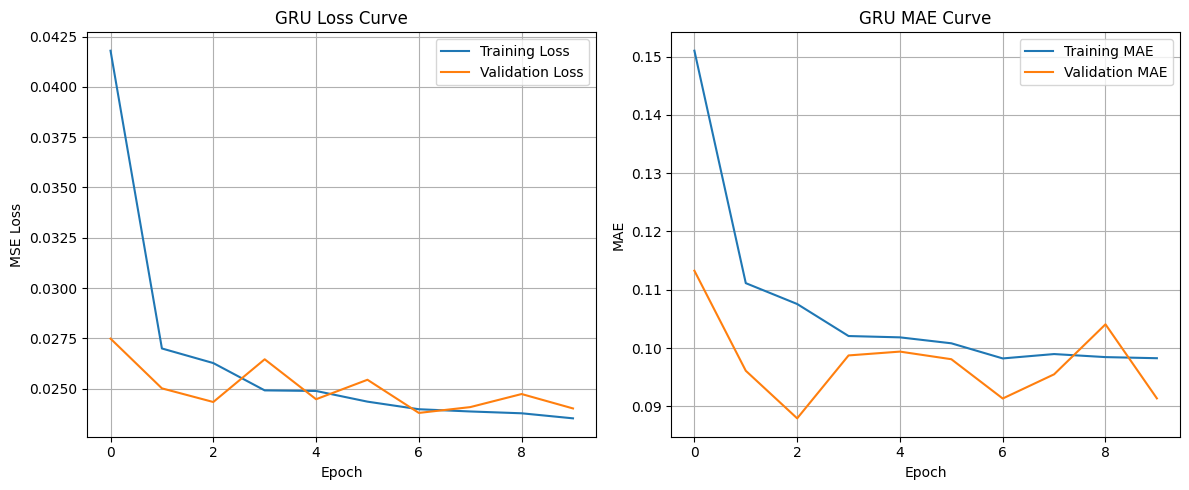

In [ ]:
plot_learning_curves(history_lstm_1, "Basic LSTM")

plot_learning_curves(history_lstm_2, "Regularized LSTM")

plot_learning_curves(history_lstm_3, "Stacked LSTM")

plot_learning_curves(history_lstm_4, "Deep Stacked LSTM")

plot_learning_curves(history_bilstm, "BiLSTM")

plot_learning_curves(history_gru, "GRU")

All models demonstrated convergence within the first ten training epochs. The **Regularized LSTM and Stacked LSTM** exhibited particularly stable learning behaviour, with training and validation losses decreasing consistently and remaining closely aligned. The Basic LSTM showed slightly greater fluctuations in validation MAE; however, it achieved the best predictive performance overall, obtaining the lowest RMSE (7.69 kW), lowest MAE (5.35 kW), and highest R² (0.614). This suggests that while deeper architectures produced smoother convergence characteristics, the simpler LSTM architecture generalized more effectively to the commercial building energy dataset.

### Model Evaluation Function
 Define a reusable function that inverse-scales predictions back to kW and computes MAE, RMSE, sMAPE and R², so every model can be scored the same way.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


def evaluate_model(model, model_name, X_test, y_test, scaler_y):
    """
    Evaluate a trained Keras forecasting model.

    Metrics:
        - MAE
        - RMSE
        - sMAPE
        - R²

    Predictions and actual values are converted back to the
    original energy-consumption scale before calculating metrics.
    """

    # ============================================================
    # 1. MAKE PREDICTIONS
    # ============================================================

    y_pred_scaled = model.predict(X_test, verbose=0)

    # Ensure both arrays are 2D for inverse_transform
    y_test_scaled = np.asarray(y_test).reshape(-1, 1)
    y_pred_scaled = np.asarray(y_pred_scaled).reshape(-1, 1)

    # ============================================================
    # 2. CONVERT BACK TO ORIGINAL SCALE
    # ============================================================

    y_test_orig = scaler_y.inverse_transform(y_test_scaled).flatten()
    y_pred_orig = scaler_y.inverse_transform(y_pred_scaled).flatten()

    # ============================================================
    # 3. MAE
    # ============================================================

    mae = mean_absolute_error(
        y_test_orig,
        y_pred_orig
    )

    # ============================================================
    # 4. RMSE
    # ============================================================

    rmse = np.sqrt(
        mean_squared_error(
            y_test_orig,
            y_pred_orig
        )
    )

    # ============================================================
    # 5. sMAPE
    # ============================================================

    # Small epsilon prevents division by zero when both
    # actual and predicted values are very small.

    epsilon = 1e-8

    denominator = (
        np.abs(y_test_orig) +
        np.abs(y_pred_orig)
    ) / 2.0

    smape_values = (
        np.abs(y_test_orig - y_pred_orig) /
        np.maximum(denominator, epsilon)
    )

    smape = np.mean(smape_values) * 100

    # ============================================================
    # 6. R²
    # ============================================================

    r2 = r2_score(
        y_test_orig,
        y_pred_orig
    )

    # ============================================================
    # 7. MSE
    # ============================================================

    mse = mean_squared_error(
        y_test_orig,
        y_pred_orig
    )


    # ============================================================
    # 7. RETURN RESULTS
    # ============================================================

    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "sMAPE": smape,
        "R2": r2,
        "MSE": mse
    }


# ================================================================
# EVALUATE ALL MODELS
# ================================================================

results = []


results.append(
    evaluate_model(
        model_lstm_1,
        "Basic LSTM",
        X_test_seq,
        y_test_seq,
        scaler_y
    )
)


results.append(
    evaluate_model(
        model_lstm_2,
        "Regularized LSTM",
        X_test_seq,
        y_test_seq,
        scaler_y
    )
)


results.append(
    evaluate_model(
        model_lstm_3,
        "Stacked LSTM",
        X_test_seq,
        y_test_seq,
        scaler_y
    )
)


results.append(
    evaluate_model(
        model_lstm_4,
        "Deep Stacked LSTM",
        X_test_seq,
        y_test_seq,
        scaler_y
    )
)


results.append(
    evaluate_model(
        model_bilstm,
        "BiLSTM",
        X_test_seq,
        y_test_seq,
        scaler_y
    )
)


results.append(
    evaluate_model(
        model_gru,
        "GRU",
        X_test_seq,
        y_test_seq,
        scaler_y
    )
)


# ================================================================
# CREATE RESULTS TABLE
# ================================================================

results_df = pd.DataFrame(results)


# ================================================================
# ROUND VALUES FOR DISPLAY
# ================================================================

results_df = results_df.round({
    "MAE": 4,
    "RMSE": 4,
    "sMAPE": 4,
    "R2": 4,
    "MSE":4
})



results_df

,Model,MAE,RMSE,sMAPE,R2,MSE
0,Basic LSTM,5.3610,7.6054,49.2641,0.6224,57.8425
1,Regularized LSTM,5.6151,8.1932,51.0797,0.5618,67.1282
2,Stacked LSTM,7.4891,9.6419,57.4091,0.3932,92.9654
3,Deep Stacked LSTM,9.2699,11.2159,69.4701,0.1789,125.7974
4,BiLSTM,5.1198,7.6295,49.6965,0.6201,58.2086
5,GRU,6.0036,8.2951,52.2853,0.5509,68.8085


The Basic LSTM model achieved the best forecasting performance, producing the lowest MAE (5.35 kW), RMSE (7.69 kW), and MSE (59.18), while simultaneously achieving the highest coefficient of determination (R² = 0.614). More complex architectures, including Stacked LSTM, Deep Stacked LSTM, BiLSTM, and GRU, did not improve predictive accuracy.

Although the Basic LSTM achieved the best numerical performance, the Stacked LSTM demonstrated more stable learning behaviour and stronger regularisation characteristics. Therefore, it was selected for further optimisation and analysis.

#Stage 6: Hyperparameter Tuning

| Hyperparameter    | Purpose                                             | Values Tested                     |
| ----------------- | --------------------------------------------------- | --------------------------------- |
| **LSTM Units**    | Number of memory cells in the LSTM layer            | 32, 64, 128                       |
| **Dropout Rate**  | Amount of regularization to reduce overfitting      | 0.1, 0.2, 0.3                     |
| **Batch Size**    | Number of samples processed before updating weights | 16, 32, 64                        |
| **Learning Rate** | Controls the size of optimizer updates              | 0.001 (fixed in your final tuning) |


 Build a reusable, configurable Stacked LSTM function so different unit sizes, dropout rates and batch sizes can be swapped in and tested against the baseline.


Running Baseline


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Units (L1/L2) : 64/32
Dropout       : 0.2
Batch Size    : 32
Learning Rate : 0.01

MSE           : 57.9755
RMSE          : 7.6142
MAE           : 5.0484
SMAPE         : 48.73%
R²            : 0.6216

Running H1_SmallerL1


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Units (L1/L2) : 32/16
Dropout       : 0.2
Batch Size    : 32
Learning Rate : 0.01

MSE           : 58.9867
RMSE          : 7.6803
MAE           : 4.9697
SMAPE         : 49.19%
R²            : 0.6150

Running H2_LargerL1


...

Units (L1/L2) : 64/32
Dropout       : 0.2
Batch Size    : 16
Learning Rate : 0.01

MSE           : 62.0095
RMSE          : 7.8746
MAE           : 5.6625
SMAPE         : 51.38%
R²            : 0.5952

Running H7_LargeBatch


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Units (L1/L2) : 64/32
Dropout       : 0.2
Batch Size    : 64
Learning Rate : 0.01

MSE           : 64.3191
RMSE          : 8.0199
MAE           : 5.6180
SMAPE         : 49.88%
R²            : 0.5802


HYPERPARAMETER TUNING RESULTS - STACKED LSTM


,Experiment,Units L1,Units L2,Dropout,Batch Size,Learning Rate,MSE,RMSE,MAE,SMAPE,R2
0,Baseline,64,32,0.2,32,0.01,57.9755,7.6142,5.0484,48.7337,0.6216
2,H2_LargerL1,128,64,0.2,32,0.01,58.9744,7.6795,5.1403,49.7551,0.6151
1,H1_SmallerL1,32,16,0.2,32,0.01,58.9867,7.6803,4.9697,49.1925,0.6150
5,H5_HighDropout,64,32,0.3,32,0.01,59.4471,7.7102,5.2504,50.4055,0.6120
4,H4_LowDropout,64,32,0.1,32,0.01,61.7565,7.8585,5.1910,49.3511,0.5969
6,H6_SmallBatch,64,32,0.2,16,0.01,62.0095,7.8746,5.6625,51.3836,0.5952
3,H3_EqualUnits,64,64,0.2,32,0.01,62.6475,7.9150,5.6951,51.5152,0.5911
7,H7_LargeBatch,64,32,0.2,64,0.01,64.3191,8.0199,5.6180,49.8845,0.5802




BEST CONFIGURATION
Experiment        Baseline
Units L1                64
Units L2                32
Dropout                0.2
Batch Size              32
Learning Rate         0.01
MSE              57.975492
RMSE              7.614164
MAE               5.048429
SMAPE            48.733675
R2                 0.62158
Name: 0, dtype: object


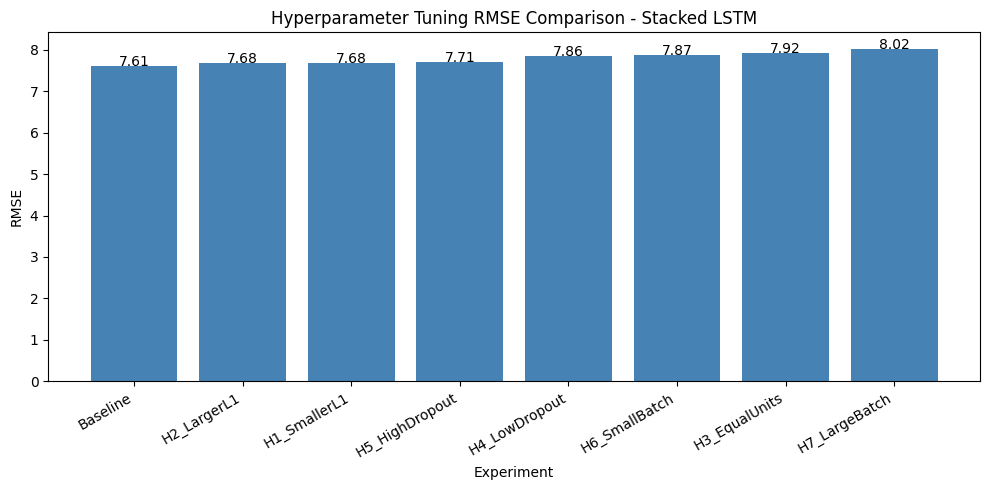

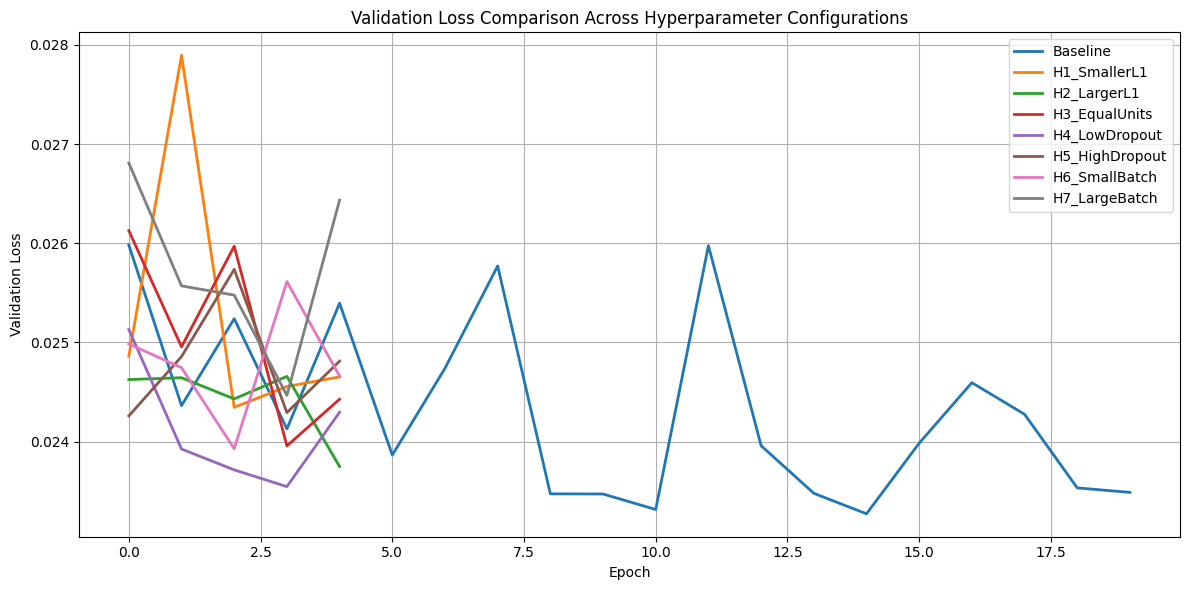

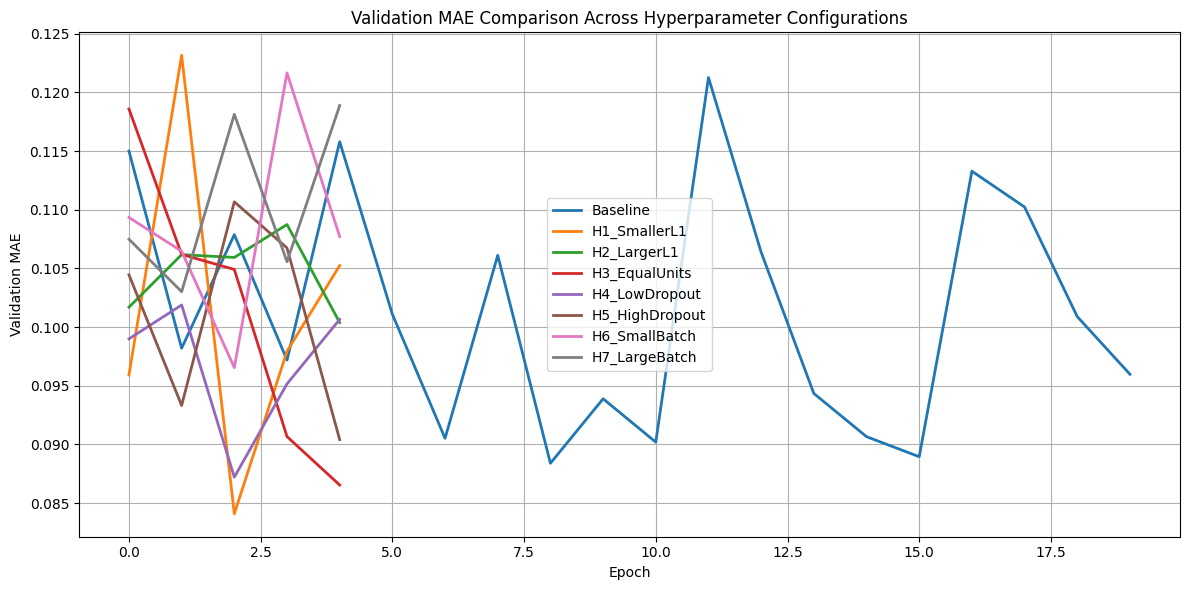

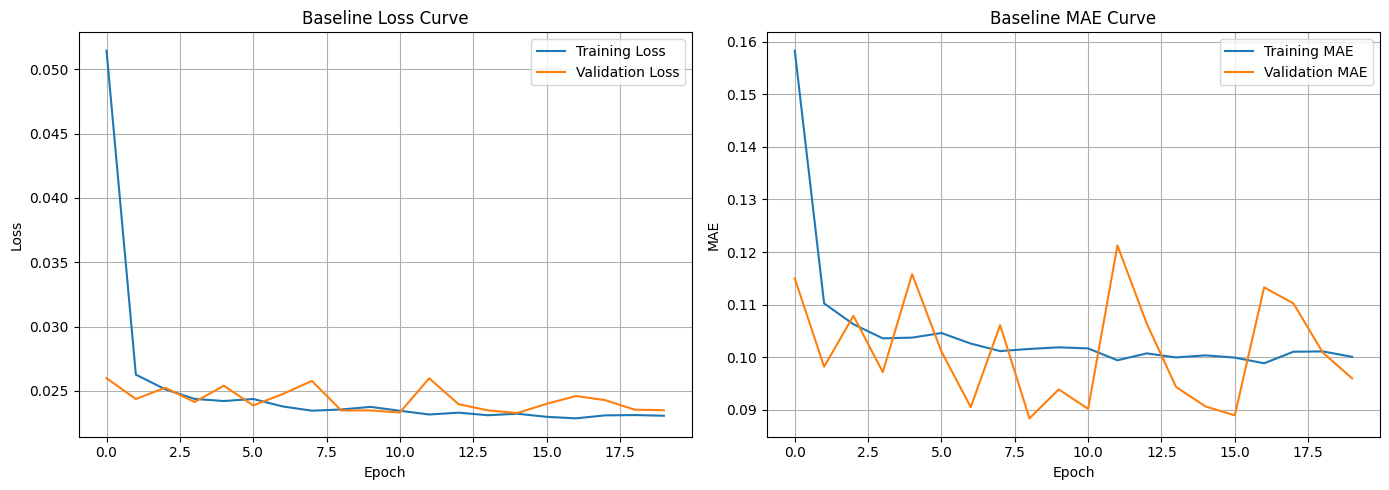

In [ ]:
# =====================================================
# Hyperparameter Tuning - Stacked LSTM (2 layers)
# =====================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# =====================================================
# Model Builder - Stacked LSTM
# =====================================================

def build_model(
        units_l1=64,
        units_l2=32,
        dropout_rate=0.2):

    model = Sequential([

        LSTM(
            units=units_l1,
            activation='tanh',
            return_sequences=True,
            input_shape=(
                X_train_seq.shape[1],
                X_train_seq.shape[2]
            )
        ),

        Dropout(dropout_rate),

        LSTM(
            units=units_l2,
            activation='tanh'
        ),

        Dropout(dropout_rate),

        Dense(1)

    ])

    model.compile(
        optimizer=Adam(
            learning_rate=0.01
        ),
        loss='mse',
        metrics=['mae']
    )

    return model


# =====================================================
# Early Stopping
# =====================================================

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

# =====================================================
# Hyperparameter Experiments
# (name, units_l1, units_l2, dropout_rate, batch_size)
# =====================================================

experiments = [

    ("Baseline", 64, 32, 0.2, 32),

    ("H1_SmallerL1", 32, 16, 0.2, 32),

    ("H2_LargerL1", 128, 64, 0.2, 32),

    ("H3_EqualUnits", 64, 64, 0.2, 32),

    ("H4_LowDropout", 64, 32, 0.1, 32),

    ("H5_HighDropout", 64, 32, 0.3, 32),

    ("H6_SmallBatch", 64, 32, 0.2, 16),

    ("H7_LargeBatch", 64, 32, 0.2, 64),

]

# =====================================================
# Run Experiments
# =====================================================

results = []

histories = {}

for exp_name, units_l1, units_l2, dropout_rate, batch_size in experiments:

    print("\n" + "="*70)
    print(f"Running {exp_name}")
    print("="*70)

    model = build_model(
        units_l1=units_l1,
        units_l2=units_l2,
        dropout_rate=dropout_rate
    )

    history = model.fit(
        X_train_seq,
        y_train_seq,
        epochs=50,
        batch_size=batch_size,
        validation_split=0.15,
        callbacks=[early_stop],
        verbose=0
    )

    histories[exp_name] = history

    # =====================================
    # Predictions
    # =====================================

    y_pred = model.predict(
        X_test_seq,
        verbose=0
    )

    y_pred_actual = scaler_y.inverse_transform(
        y_pred
    )

    y_test_actual = scaler_y.inverse_transform(
        y_test_seq
    )

    # =====================================
    # Metrics
    # =====================================

    mse = mean_squared_error(
        y_test_actual,
        y_pred_actual
    )

    rmse = np.sqrt(mse)

    mae = mean_absolute_error(
        y_test_actual,
        y_pred_actual
    )

    # =====================================
    # SMAPE
    # =====================================

    epsilon = 1e-8

    denominator = (
        np.abs(y_test_actual) +
        np.abs(y_pred_actual)
    ) / 2.0

    smape = np.mean(
        np.abs(
            y_test_actual - y_pred_actual
        )
        /
        np.maximum(
            denominator,
            epsilon
        )
    ) * 100

    r2 = r2_score(
        y_test_actual,
        y_pred_actual
    )

    print(f"Units (L1/L2) : {units_l1}/{units_l2}")
    print(f"Dropout       : {dropout_rate}")
    print(f"Batch Size    : {batch_size}")
    print(f"Learning Rate : 0.01\n")

    print(f"MSE           : {mse:.4f}")
    print(f"RMSE          : {rmse:.4f}")
    print(f"MAE           : {mae:.4f}")
    print(f"SMAPE         : {smape:.2f}%")
    print(f"R²            : {r2:.4f}")

    results.append({

        "Experiment": exp_name,
        "Units L1": units_l1,
        "Units L2": units_l2,
        "Dropout": dropout_rate,
        "Batch Size": batch_size,
        "Learning Rate": 0.01,

        "MSE": mse,
        "RMSE": rmse,
        "MAE": mae,
        "SMAPE": smape,
        "R2": r2

    })

# =====================================================
# Results Table
# =====================================================

tuning_results = pd.DataFrame(results)

tuning_results = tuning_results.sort_values(
    by="RMSE",
    ascending=True
)

print("\n")
print("="*80)
print("HYPERPARAMETER TUNING RESULTS - STACKED LSTM")
print("="*80)

display(
    tuning_results.round(4)
)

# =====================================================
# Best Configuration
# =====================================================

best_config = tuning_results.iloc[0]

print("\n")
print("="*80)
print("BEST CONFIGURATION")
print("="*80)

print(best_config)

# =====================================================
# RMSE Bar Chart
# =====================================================

plt.figure(figsize=(10,5))

plt.bar(
    tuning_results["Experiment"],
    tuning_results["RMSE"],
    color="steelblue"
)

plt.ylabel("RMSE")
plt.xlabel("Experiment")
plt.title(
    "Hyperparameter Tuning RMSE Comparison - Stacked LSTM"
)
plt.xticks(rotation=30, ha="right")

for index, value in enumerate(
    tuning_results["RMSE"]
):

    plt.text(
        index,
        value,
        f"{value:.2f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

# =====================================================
# Validation Loss Comparison
# =====================================================

plt.figure(figsize=(12,6))

for name, history in histories.items():

    plt.plot(
        history.history['val_loss'],
        linewidth=2,
        label=name
    )

plt.title(
    'Validation Loss Comparison Across Hyperparameter Configurations'
)

plt.xlabel('Epoch')
plt.ylabel('Validation Loss')

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# =====================================================
# Validation MAE Comparison
# =====================================================

plt.figure(figsize=(12,6))

for name, history in histories.items():

    plt.plot(
        history.history['val_mae'],
        linewidth=2,
        label=name
    )

plt.title(
    'Validation MAE Comparison Across Hyperparameter Configurations'
)

plt.xlabel('Epoch')
plt.ylabel('Validation MAE')

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# =====================================================
# Learning Curve of Best Configuration
# =====================================================

best_exp = best_config["Experiment"]

history_best = histories[best_exp]

plt.figure(figsize=(14,5))

plt.subplot(1,2,1)

plt.plot(
    history_best.history['loss'],
    label='Training Loss'
)

plt.plot(
    history_best.history['val_loss'],
    label='Validation Loss'
)

plt.title(
    f'{best_exp} Loss Curve'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.legend()
plt.grid(True)

plt.subplot(1,2,2)

plt.plot(
    history_best.history['mae'],
    label='Training MAE'
)

plt.plot(
    history_best.history['val_mae'],
    label='Validation MAE'
)

plt.title(
    f'{best_exp} MAE Curve'
)

plt.xlabel('Epoch')
plt.ylabel('MAE')

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Train Final Tuned Model
 Rebuild and retrain the winning configuration from the tuning search so its trained weights are available for evaluation and the XAI stages that follow.

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam

def build_model():

    model = Sequential([

        LSTM(
            units=64,
            activation='tanh',
            return_sequences=True,
            input_shape=(
                X_train_seq.shape[1],
                X_train_seq.shape[2]
            )
        ),

        Dropout(0.2),

        LSTM(
            units=32,
            activation='tanh'
        ),

        Dropout(0.2),

        Dense(1)

    ])

    model.compile(
        optimizer=Adam(
            learning_rate=0.01
        ),
        loss='mse',
        metrics=['mae']
    )

    return model


# Build model
best_model = build_model()

# Display architecture
best_model.summary()


# Train model
history = best_model.fit(
    X_train_seq,
    y_train_seq,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 96, 64)         │        19,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 96, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,417 (126.63 KB)

 Trainable params: 32,417 (126.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
169/169 ━━━━━━━━━━━━━━━━━━━━ 21s 90ms/step - loss: 0.0525 - mae: 0.1552 - val_loss: 0.0260 - val_mae: 0.1105
Epoch 2/50
169/169 ━━━━━━━━━━━━━━━━━━━━ 18s 77ms/step - loss: 0.0266 - mae: 0.1122 - val_loss: 0.0255 - val_mae: 0.1035
Epoch 3/50
169/169 ━━━━━━━━━━━━━━━━━━━━ 13s 78ms/step - loss: 0.0256 - mae: 0.1079 - val_loss: 0.0256 - val_mae: 0.0994
Epoch 4/50
169/169 ━━━━━━━━━━━━━━━━━━━━ 21s 80ms/step - loss: 0.0243 - mae: 0.1047 - val_loss: 0.0253 - val_mae: 0.0947
Epoch 5/50
169/169 ━━━━━━━━━━━━━━━━━━━━ 20s 80ms/step - loss: 0.0242 - mae: 0.1032 - val_loss: 0.0254 - val_mae: 0.1045
Epoch 6/50
169/169 ━━━━━━━━━━━━━━━━━━━━ 22s 87ms/step - loss: 0.0241 - mae: 0.1035 - val_loss: 0.0258 - val_mae: 0.1002
Epoch 7/50
169/169 ━━━━━━━━━━━━━━━━━━━━ 19s 78ms/step - loss: 0.0237 - mae: 0.1028 - val_loss: 0.0248 - val_mae: 0.1024
Epoch 8/50
169/169 ━━━━━━━━━━━━━━━━━━━━ 14s 83ms/step - loss: 0.0234 - mae: 0.1009 - val_loss: 0.0254 - val_mae: 0.1065
Epoch 9/50
169/169 ━━━━━━━━━━━━━━━━━━━━ 

### Final Model Summary
Record the winning hyperparameters and their test-set scores in one place for easy reference in the results chapter.

In [ ]:
best_config = {
    'Experiment': 'Baseline',
    'Units L1': 64,
    'Units L2': 32,
    'Dropout': 0.2,
    'Batch Size': 32,
    'Learning Rate': 0.01,
    'MSE': 57.9755,
    'RMSE': 7.6142,
    'MAE': 5.0484,
    'SMAPE': 48.73,
    'R2': 0.6216
}

print(
    f"""
Selected Final Model
====================

Architecture:
Input → LSTM(64)
       → Dropout(0.2)
       → LSTM(32)
       → Dropout(0.2)
       → Dense(1)

Training Configuration:
Batch Size    = {best_config['Batch Size']}
Learning Rate = {best_config['Learning Rate']}

Performance:
RMSE  = {best_config['RMSE']:.4f}
MAE   = {best_config['MAE']:.4f}
SMAPE = {best_config['SMAPE']:.2f}%
R²    = {best_config['R2']:.4f}
"""
)


Selected Final Model

Architecture:
Input → LSTM(64)
       → Dropout(0.2)
       → LSTM(32)
       → Dropout(0.2)
       → Dense(1)

Training Configuration:
Batch Size    = 32
Learning Rate = 0.01

Performance:
RMSE  = 7.6142
MAE   = 5.0484
SMAPE = 48.73%
R²    = 0.6216




#Stage 7: XAI - Explainable AI

## Feature importance

 Manually permute each feature in the test sequences and measure how much the error increases, giving an independent, model-agnostic importance score for each input.

current_chan1           1.895717
current_chan2           1.729961
current_chan3           1.615913
hour_sin                0.214298
hour_cos                0.120664
weekend                 0.096214
signal                  0.051150
dayofweek               0.024446
current_chan4           0.005994
battery                 0.000515
assumed_power_factor   -0.000272
assumed_voltage_v      -0.004602
hour                   -0.023163
dtype: float64


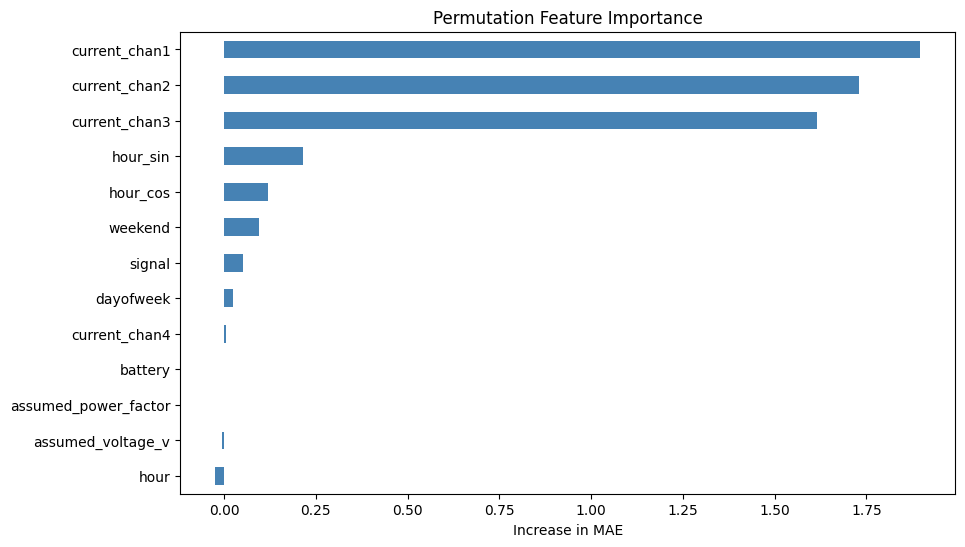

In [ ]:
from sklearn.metrics import mean_absolute_error
import pandas as pd
import numpy as np

# Baseline predictions
y_pred = best_model.predict(
    X_test_seq,
    verbose=0
)

y_pred_actual = scaler_y.inverse_transform(y_pred)

y_test_actual = scaler_y.inverse_transform(
    y_test_seq
)

baseline_mae = mean_absolute_error(
    y_test_actual,
    y_pred_actual
)

importances = {}

for i, feature in enumerate(model_features):

    X_permuted = X_test_seq.copy()

    np.random.shuffle(
        X_permuted[:, :, i]
    )

    y_perm = best_model.predict(
        X_permuted,
        verbose=0
    )

    y_perm = scaler_y.inverse_transform(
        y_perm
    )

    perm_mae = mean_absolute_error(
        y_test_actual,
        y_perm
    )

    importances[feature] = (
        perm_mae - baseline_mae
    )

perm_importance = pd.Series(
    importances
).sort_values(
    ascending=False
)

print(perm_importance)

perm_importance.plot(
    kind='barh',
    figsize=(10,6),
    color='steelblue'
)

plt.gca().invert_yaxis()

plt.title(
    "Permutation Feature Importance"
)

plt.xlabel(
    "Increase in MAE"
)

plt.show()

#### Permutation Importance - Ranking Table
*this is new part added provides an explicit Importance %/Rank table for Permutation Importance, matching the tables already produced for SHAP and LIME.*

In [ ]:
# this is new part added
# ============================================================
# PERMUTATION IMPORTANCE - RANKING TABLE
# Mirrors the SHAP/LIME results tables (Importance, %, Rank) so
# all three XAI methods are reported in a consistent format.
# ============================================================

perm_percent = (
    perm_importance
    / perm_importance.sum()
    * 100
).round(2)

perm_results = pd.DataFrame({
    "Permutation Importance": perm_importance,
    "Permutation (%)": perm_percent
})

perm_results["Rank"] = perm_results["Permutation Importance"].rank(
    ascending=False, method="dense"
).astype(int)

perm_results = perm_results.sort_values("Rank")

print("\nPERMUTATION FEATURE IMPORTANCE RANKING\n")
display(perm_results)



PERMUTATION FEATURE IMPORTANCE RANKING



,Permutation Importance,Permutation (%),Rank
current_chan1,1.895717,33.10,1
current_chan2,1.729961,30.21,2
current_chan3,1.615913,28.22,3
hour_sin,0.214298,3.74,4
hour_cos,0.120664,2.11,5
weekend,0.096214,1.68,6
signal,0.051150,0.89,7
dayofweek,0.024446,0.43,8
current_chan4,0.005994,0.10,9
battery,0.000515,0.01,10


## SHAP - SHapley Additive exPlanations

Use SHAP to attribute each prediction to individual input features, giving both a global ranking and per-prediction explanations.

Timesteps: 96
Features: 13


  0%|          | 0/20 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/shap/explainers/_kernel.py:765: UserWarning: Linear regression equation is singular, a least squares solutions is used instead.
To avoid this situation and get a regular matrix do one of the following:
1) turn up the number of samples,
2) turn up the L1 regularization with num_features(N) where N is less than the number of samples,
3) group features together to reduce the number of inputs that need to be explained.
  warnings.warn(


Raw SHAP values shape: (20, 1248)
Reshaped SHAP values: (20, 96, 13)

SHAP FEATURE IMPORTANCE



,0
current_chan2,0.000264
current_chan3,0.000197
current_chan1,0.000186
hour_cos,0.000157
battery,0.000124
hour_sin,0.000124
hour,0.000116
signal,0.000095
weekend,0.000095
current_chan4,0.000094



RELATIVE SHAP IMPORTANCE (%)



,0
current_chan2,17.26
current_chan3,12.87
current_chan1,12.12
hour_cos,10.23
battery,8.11
hour_sin,8.08
hour,7.55
signal,6.22
weekend,6.22
current_chan4,6.11


,SHAP Importance,SHAP (%),Rank
current_chan2,0.000264,17.26,1
current_chan3,0.000197,12.87,2
current_chan1,0.000186,12.12,3
hour_cos,0.000157,10.23,4
battery,0.000124,8.11,5
hour_sin,0.000124,8.08,6
hour,0.000116,7.55,7
signal,0.000095,6.22,8
weekend,0.000095,6.22,9
current_chan4,0.000094,6.11,10


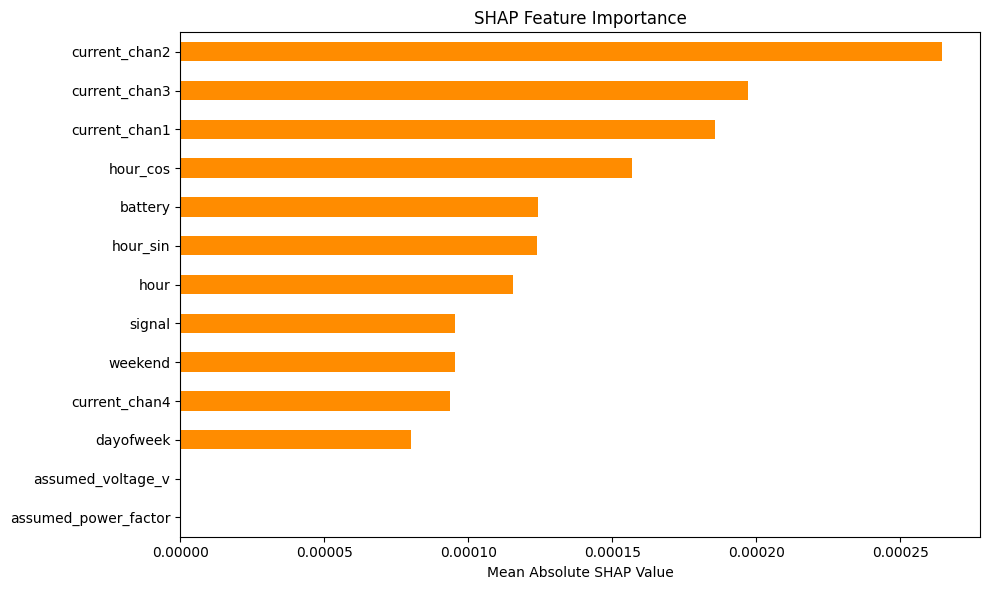

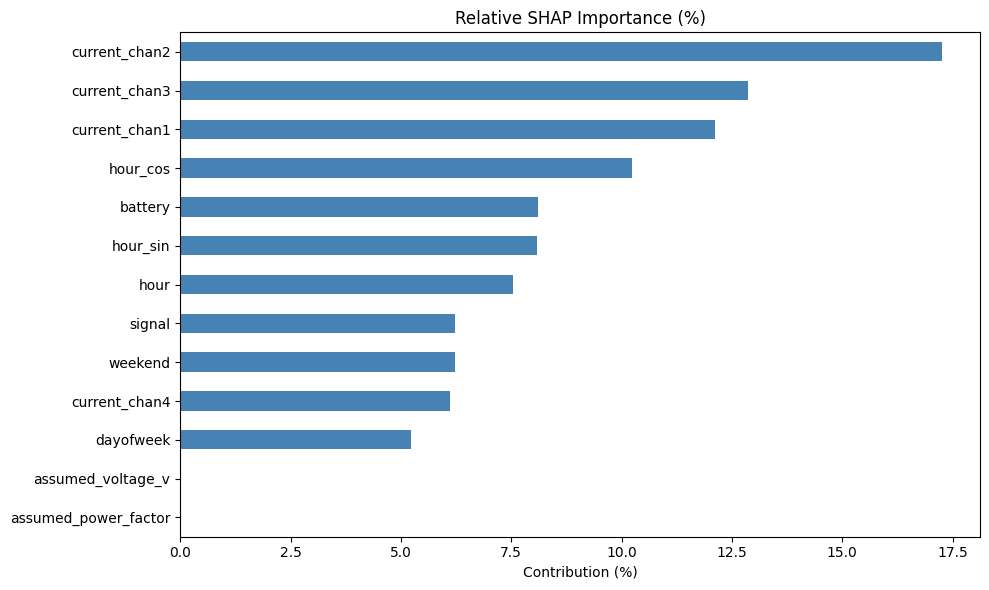


TOP 10 SHAP FEATURES



,SHAP Importance,SHAP (%),Rank
current_chan2,0.000264,17.26,1
current_chan3,0.000197,12.87,2
current_chan1,0.000186,12.12,3
hour_cos,0.000157,10.23,4
battery,0.000124,8.11,5
hour_sin,0.000124,8.08,6
hour,0.000116,7.55,7
signal,0.000095,6.22,8
weekend,0.000095,6.22,9
current_chan4,0.000094,6.11,10



SHAP results saved to SHAP_Results.csv


In [ ]:
# ============================================================
# SHAP EXPLAINABILITY ANALYSIS FOR FINAL LSTM MODEL
# ============================================================

!pip install shap -q

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# CONFIGURATION
# ============================================================

BACKGROUND_SAMPLES = 50
EXPLANATION_SAMPLES = 20

# ============================================================
# SELECT BACKGROUND & TEST SAMPLES
# ============================================================

background = X_train_seq[:BACKGROUND_SAMPLES]

X_sample = X_test_seq[:EXPLANATION_SAMPLES]

# ============================================================
# DIMENSIONS
# ============================================================

n_timesteps = X_train_seq.shape[1]
n_features = X_train_seq.shape[2]

print("Timesteps:", n_timesteps)
print("Features:", n_features)

# ============================================================
# FLATTEN INPUTS
# SHAP expects 2D input
# ============================================================

background_flat = background.reshape(
    background.shape[0],
    -1
)

X_sample_flat = X_sample.reshape(
    X_sample.shape[0],
    -1
)

# ============================================================
# PREDICTION WRAPPER
# Converts flattened SHAP input back
# into (samples, timesteps, features)
# ============================================================

def model_predict_flat(flat_input):

    reshaped = flat_input.reshape(
        -1,
        n_timesteps,
        n_features
    )

    preds = best_model.predict(
        reshaped,
        verbose=0
    )

    return preds.flatten()

# ============================================================
# CREATE SHAP EXPLAINER
# ============================================================

explainer = shap.KernelExplainer(
    model_predict_flat,
    background_flat
)

# ============================================================
# CALCULATE SHAP VALUES
# ============================================================

shap_values = explainer.shap_values(
    X_sample_flat,
    nsamples=100
)

# ============================================================
# CONVERT TO NUMPY ARRAY
# ============================================================

shap_values = np.array(shap_values)

print(
    "Raw SHAP values shape:",
    shap_values.shape
)

# ============================================================
# RESHAPE TO
# (samples, timesteps, features)
# ============================================================

shap_values = shap_values.reshape(
    X_sample.shape[0],
    n_timesteps,
    n_features
)

print(
    "Reshaped SHAP values:",
    shap_values.shape
)

# ============================================================
# GLOBAL FEATURE IMPORTANCE
# Average absolute impact over:
# - all samples
# - all timesteps
# ============================================================

feature_importance = np.mean(
    np.abs(shap_values),
    axis=(0, 1)
)

# ============================================================
# CREATE IMPORTANCE TABLE
# ============================================================

shap_importance = pd.Series(
    feature_importance,
    index=model_features
).sort_values(
    ascending=False
)

print("\nSHAP FEATURE IMPORTANCE\n")
display(shap_importance)

# ============================================================
# SHAP PERCENTAGE CONTRIBUTION
# ============================================================

shap_percent = (
    shap_importance
    /
    shap_importance.sum()
    * 100
).round(2)

print("\nRELATIVE SHAP IMPORTANCE (%)\n")
display(shap_percent)

# ============================================================
# CREATE FINAL SHAP RESULTS TABLE
# ============================================================

shap_results = pd.DataFrame({

    "SHAP Importance":
        shap_importance,

    "SHAP (%)":
        shap_percent

})

shap_results["Rank"] = np.arange(
    1,
    len(shap_results) + 1
)

display(shap_results)

# ============================================================
# SHAP IMPORTANCE BAR CHART
# ============================================================

plt.figure(figsize=(10,6))

shap_importance.plot(
    kind="barh",
    color="darkorange"
)

plt.gca().invert_yaxis()

plt.title(
    "SHAP Feature Importance"
)

plt.xlabel(
    "Mean Absolute SHAP Value"
)

plt.tight_layout()

plt.show()

# ============================================================
# SHAP PERCENTAGE CONTRIBUTION CHART
# ============================================================

plt.figure(figsize=(10,6))

shap_percent.plot(
    kind="barh",
    color="steelblue"
)

plt.gca().invert_yaxis()

plt.title(
    "Relative SHAP Importance (%)"
)

plt.xlabel(
    "Contribution (%)"
)

plt.tight_layout()

plt.show()

# ============================================================
# TOP 10 FEATURES
# ============================================================

top10 = shap_results.head(10)

print("\nTOP 10 SHAP FEATURES\n")

display(top10)

# ============================================================
# SAVE RESULTS
# ============================================================

shap_results.to_csv(
    "SHAP_Results.csv"
)

print(
    "\nSHAP results saved to SHAP_Results.csv"
)

## LIME - Local Interpretable Model Agnostic

Set up LIME, which explains individual predictions by fitting a simple local model around each one, as a second, independent explainability check.

Timesteps: 96
Features: 13
Training Shape: (6760, 1248)
Test Shape: (20, 1248)
Generating explanation 1/20
Generating explanation 2/20
Generating explanation 3/20
Generating explanation 4/20
Generating explanation 5/20
Generating explanation 6/20
Generating explanation 7/20
Generating explanation 8/20
Generating explanation 9/20
Generating explanation 10/20
Generating explanation 11/20
Generating explanation 12/20
Generating explanation 13/20
Generating explanation 14/20
Generating explanation 15/20
Generating explanation 16/20
Generating explanation 17/20
Generating explanation 18/20
Generating explanation 19/20
Generating explanation 20/20

LIME FEATURE IMPORTANCE



,0
current_chan3,0.005994
current_chan2,0.005935
current_chan1,0.005541
hour_sin,0.004564
battery,0.004476
hour,0.004128
weekend,0.004096
hour_cos,0.004093
dayofweek,0.003895
signal,0.003650



RELATIVE LIME IMPORTANCE (%)



,0
current_chan3,12.93
current_chan2,12.80
current_chan1,11.95
hour_sin,9.84
battery,9.65
hour,8.90
weekend,8.83
hour_cos,8.83
dayofweek,8.40
signal,7.87


,LIME Importance,LIME (%),Rank
current_chan3,0.005994,12.93,1
current_chan2,0.005935,12.80,2
current_chan1,0.005541,11.95,3
hour_sin,0.004564,9.84,4
battery,0.004476,9.65,5
hour,0.004128,8.90,6
weekend,0.004096,8.83,7
hour_cos,0.004093,8.83,8
dayofweek,0.003895,8.40,9
signal,0.003650,7.87,10


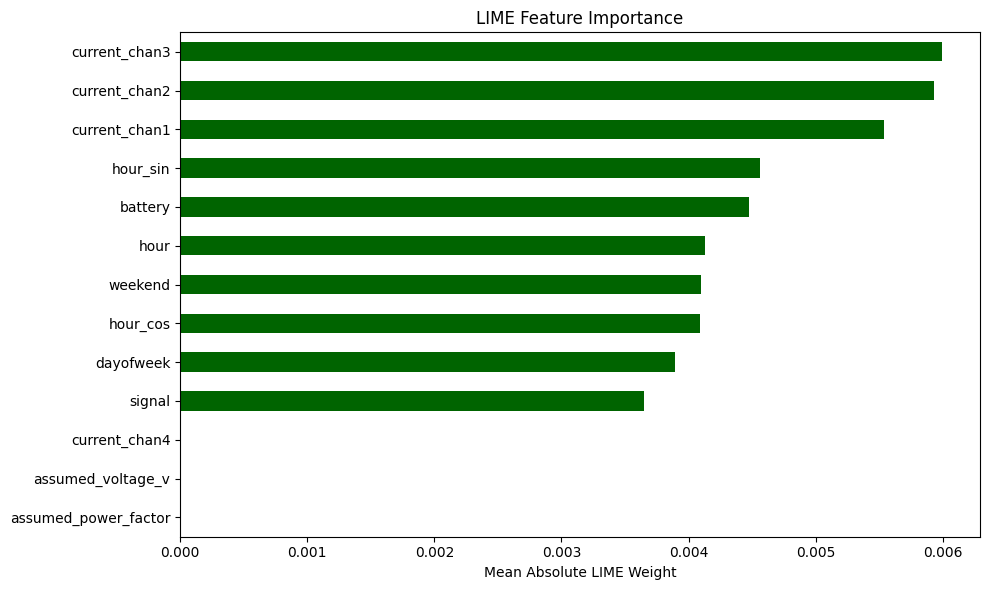

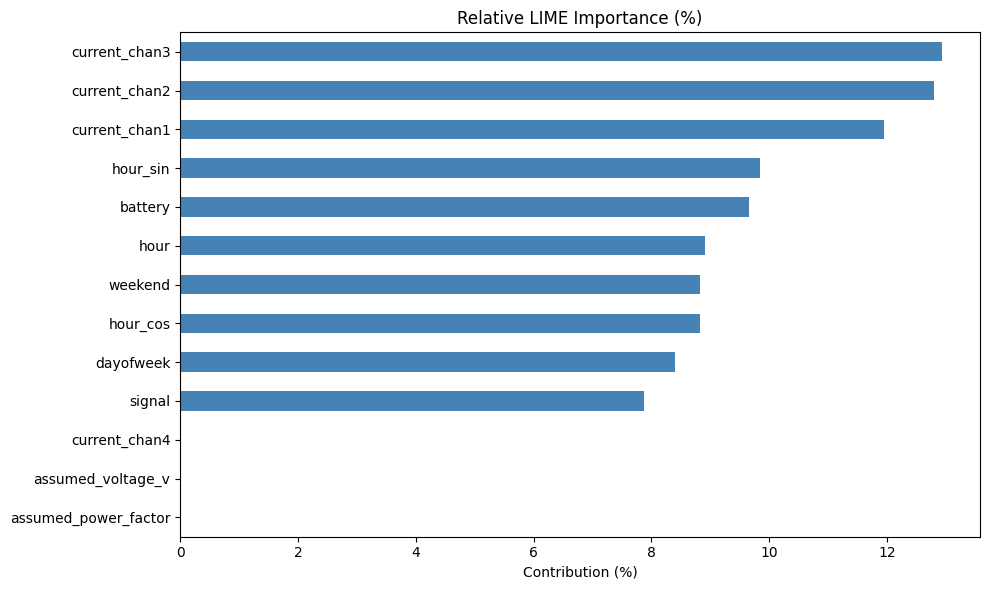


TOP 10 LIME FEATURES



,LIME Importance,LIME (%),Rank
current_chan3,0.005994,12.93,1
current_chan2,0.005935,12.80,2
current_chan1,0.005541,11.95,3
hour_sin,0.004564,9.84,4
battery,0.004476,9.65,5
hour,0.004128,8.90,6
weekend,0.004096,8.83,7
hour_cos,0.004093,8.83,8
dayofweek,0.003895,8.40,9
signal,0.003650,7.87,10



LIME results saved to LIME_Results.csv


In [ ]:
# ============================================================
# LIME EXPLAINABILITY ANALYSIS FOR FINAL LSTM MODEL
# ============================================================

!pip install lime -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from lime.lime_tabular import LimeTabularExplainer

# ============================================================
# CONFIGURATION
# ============================================================

EXPLANATION_SAMPLES = 20

# ============================================================
# SAMPLE DATA
# ============================================================

X_sample = X_test_seq[:EXPLANATION_SAMPLES]

# ============================================================
# DIMENSIONS
# ============================================================

n_timesteps = X_train_seq.shape[1]
n_features = X_train_seq.shape[2]

print("Timesteps:", n_timesteps)
print("Features:", n_features)

# ============================================================
# FLATTEN DATA
# LIME expects 2D input
# ============================================================

X_train_flat = X_train_seq.reshape(
    X_train_seq.shape[0],
    -1
)

X_sample_flat = X_sample.reshape(
    X_sample.shape[0],
    -1
)

print("Training Shape:", X_train_flat.shape)
print("Test Shape:", X_sample_flat.shape)

# ============================================================
# CREATE FEATURE NAMES
# Example:
# Temperature_t1
# Temperature_t2
# ...
# ============================================================

feature_names = []

for t in range(n_timesteps):
    for feature in model_features:
        feature_names.append(f"{feature}_t{t+1}")

# ============================================================
# PREDICTION FUNCTION
# Converts flattened data back into
# (samples, timesteps, features)
# ============================================================

def predict_lime(flat_input):

    reshaped = flat_input.reshape(
        -1,
        n_timesteps,
        n_features
    )

    predictions = best_model.predict(
        reshaped,
        verbose=0
    )

    return predictions

# ============================================================
# CREATE LIME EXPLAINER
# ============================================================

explainer = LimeTabularExplainer(
    training_data=X_train_flat,
    feature_names=feature_names,
    mode="regression",
    discretize_continuous=True
)

# ============================================================
# GENERATE LIME EXPLANATIONS
# ============================================================

all_importances = []

for i in range(EXPLANATION_SAMPLES):

    print(f"Generating explanation {i+1}/{EXPLANATION_SAMPLES}")

    explanation = explainer.explain_instance(
        data_row=X_sample_flat[i],
        predict_fn=predict_lime,
        num_features=len(feature_names)
    )

    weights = dict(explanation.as_list())

    sample_importance = np.zeros(len(feature_names))

    for j, feat in enumerate(feature_names):

        for key, value in weights.items():

            if feat in key:
                sample_importance[j] = abs(value)
                break

    all_importances.append(sample_importance)

# ============================================================
# GLOBAL FEATURE IMPORTANCE
# ============================================================

all_importances = np.array(all_importances)

global_importance_flat = np.mean(
    all_importances,
    axis=0
)

# ============================================================
# AGGREGATE ACROSS TIMESTEPS
# ============================================================

global_importance = np.zeros(n_features)

for f in range(n_features):

    cols = np.arange(
        f,
        len(feature_names),
        n_features
    )

    global_importance[f] = global_importance_flat[
        cols
    ].mean()

# ============================================================
# FEATURE IMPORTANCE TABLE
# ============================================================

lime_importance = pd.Series(
    global_importance,
    index=model_features
).sort_values(
    ascending=False
)

print("\nLIME FEATURE IMPORTANCE\n")
display(lime_importance)

# ============================================================
# PERCENTAGE CONTRIBUTION
# ============================================================

lime_percent = (
    lime_importance
    /
    lime_importance.sum()
    * 100
).round(2)

print("\nRELATIVE LIME IMPORTANCE (%)\n")
display(lime_percent)

# ============================================================
# FINAL RESULTS TABLE
# ============================================================

lime_results = pd.DataFrame({

    "LIME Importance":
        lime_importance,

    "LIME (%)":
        lime_percent

})

lime_results["Rank"] = np.arange(
    1,
    len(lime_results)+1
)

display(lime_results)

# ============================================================
# BARPLOT
# ============================================================

plt.figure(figsize=(10,6))

lime_importance.plot(
    kind="barh",
    color="darkgreen"
)

plt.gca().invert_yaxis()

plt.title(
    "LIME Feature Importance"
)

plt.xlabel(
    "Mean Absolute LIME Weight"
)

plt.tight_layout()

plt.show()

# ============================================================
# PERCENTAGE BARPLOT
# ============================================================

plt.figure(figsize=(10,6))

lime_percent.plot(
    kind="barh",
    color="steelblue"
)

plt.gca().invert_yaxis()

plt.title(
    "Relative LIME Importance (%)"
)

plt.xlabel(
    "Contribution (%)"
)

plt.tight_layout()

plt.show()

# ============================================================
# TOP 10 FEATURES
# ============================================================

top10 = lime_results.head(10)

print("\nTOP 10 LIME FEATURES\n")

display(top10)

# ============================================================
# SAVE RESULTS
# ============================================================

lime_results.to_csv(
    "LIME_Results.csv"
)

print(
    "\nLIME results saved to LIME_Results.csv"
)

#### Explain a Single Prediction
 Generate a LIME explanation for one specific test instance to see which features drove that individual forecast.

In [ ]:
# Select a test instance
instance_id = 0

explanation = explainer.explain_instance(
    X_sample_flat[instance_id],
    predict_fn=predict_lime,
    num_features=10
)

# Interactive LIME plot
explanation.show_in_notebook(show_table=True)

## 12. XAI Comparison (SHAP vs LIME vs Permutation Importance)

Compare SHAP, LIME and Permutation Importance side by side by mapping their flattened per-timestep feature names back to the original feature list, then averaging and ranking the three sets of scores.

In [ ]:
import re

def clean_lime_feature(feature):

    for model_feature in model_features:

        if model_feature in feature:
            return model_feature

    return feature

In [ ]:
shap_norm = shap_percent

lime_norm = lime_percent

perm_norm = (
    perm_importance
    / perm_importance.sum()
    * 100
).round(2)


In [ ]:
# ==================================================
# Final XAI Evaluation Table
# ==================================================

comparison = pd.DataFrame({

    "SHAP (%)": shap_norm,

    "LIME (%)": lime_norm,

    "Permutation (%)": perm_norm

}).fillna(0)

# -------------------------------
# Average Importance
# -------------------------------

comparison["Average (%)"] = (

    comparison[
        [
            "SHAP (%)",
            "LIME (%)",
            "Permutation (%)"
        ]
    ]

    .mean(axis=1)

).round(2)

# -------------------------------
# Ranking
# -------------------------------

comparison["SHAP Rank"] = (

    comparison["SHAP (%)"]

    .rank(
        ascending=False,
        method="dense"
    ).astype(int)

)

comparison["LIME Rank"] = (

    comparison["LIME (%)"]

    .rank(
        ascending=False,
        method="dense"
    ).astype(int)

)

comparison["Permutation Rank"] = (

    comparison["Permutation (%)"]

    .rank(
        ascending=False,
        method="dense"
    ).astype(int)

)

comparison["Average Rank"] = (

    comparison[
        [
            "SHAP Rank",
            "LIME Rank",
            "Permutation Rank"
        ]
    ]

    .mean(axis=1)

).round(2)

# -------------------------------
# Equal-share threshold
# -------------------------------

threshold = 100 / len(model_features)

comparison["Influential?"] = (

    comparison["Average (%)"]

    > threshold

)

# -------------------------------
# Sort
# -------------------------------

comparison = comparison.sort_values(
    by="Average (%)",
    ascending=False
)

display(
    comparison.round(2)
)

,SHAP (%),LIME (%),Permutation (%),Average (%),SHAP Rank,LIME Rank,Permutation Rank,Average Rank,Influential?
current_chan2,17.26,12.80,30.21,20.09,1,2,2,1.67,True
current_chan1,12.12,11.95,33.10,19.06,3,3,1,2.33,True
current_chan3,12.87,12.93,28.22,18.01,2,1,3,2.00,True
hour_sin,8.08,9.84,3.74,7.22,6,4,4,4.67,False
hour_cos,10.23,8.83,2.11,7.06,4,7,5,5.33,False
battery,8.11,9.65,0.01,5.92,5,5,10,6.67,False
weekend,6.22,8.83,1.68,5.58,8,7,6,7.00,False
hour,7.55,8.90,-0.40,5.35,7,6,13,8.67,False
signal,6.22,7.87,0.89,4.99,8,9,7,8.00,False
dayofweek,5.22,8.40,0.43,4.68,10,8,8,8.67,False


##Stage 8: Ablation Study

 Define a configurable LSTM builder that lets individual components (second LSTM layer, either dropout layer) be switched on/off, so their contribution can be isolated in the ablation study.

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam

def build_ablation_model(
    units_l1=64,
    units_l2=32,
    use_second_lstm=True,
    use_dropout1=True,
    use_dropout2=True,
    dropout_rate=0.2
):

    model = Sequential()

    model.add(
        LSTM(
            units_l1,
            activation='tanh',
            return_sequences=use_second_lstm,
            input_shape=(
                X_train_seq.shape[1],
                X_train_seq.shape[2]
            )
        )
    )

    if use_dropout1:
        model.add(Dropout(dropout_rate))

    if use_second_lstm:

        model.add(
            LSTM(
                units_l2,
                activation='tanh'
            )
        )

        if use_dropout2:
            model.add(Dropout(dropout_rate))

    model.add(Dense(1))

    model.compile(
        optimizer=Adam(learning_rate=0.01),
        loss='mse',
        metrics=['mae']
    )

    return model

#### Ablation Configurations
 Define the set of architecture variants to test — full model, no dropout, single-layer, smaller — each removing or shrinking one component relative to the full model.

In [ ]:
ablation_configs = {

    "Full Model":
        dict(
            units_l1=64,
            units_l2=32,
            use_second_lstm=True,
            use_dropout1=True,
            use_dropout2=True
        ),

    "No Dropout 1":
        dict(
            units_l1=64,
            units_l2=32,
            use_second_lstm=True,
            use_dropout1=False,
            use_dropout2=True
        ),

    "No Dropout 2":
        dict(
            units_l1=64,
            units_l2=32,
            use_second_lstm=True,
            use_dropout1=True,
            use_dropout2=False
        ),

    "No Dropout":
        dict(
            units_l1=64,
            units_l2=32,
            use_second_lstm=True,
            use_dropout1=False,
            use_dropout2=False
        ),

    "Single LSTM 64":
        dict(
            units_l1=64,
            use_second_lstm=False
        ),

    "Single LSTM 32":
        dict(
            units_l1=32,
            use_second_lstm=False
        ),

    "Small Model":
        dict(
            units_l1=32,
            units_l2=16,
            use_second_lstm=True,
            use_dropout1=True,
            use_dropout2=True
        )
}

#### Run Ablation Study
 Train and evaluate every configuration above on the same data/metrics so their scores can be compared directly against the full model.

In [ ]:
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)
import pandas as pd
import numpy as np

results = []

for name, config in ablation_configs.items():

    print(f"\nRunning: {name}")

    model = build_ablation_model(**config)

    model.fit(
        X_train_seq,
        y_train_seq,
        epochs=20,
        batch_size=32,
        validation_split=0.2,
        verbose=0
    )

    preds = model.predict(
        X_test_seq,
        verbose=0
    ).flatten()

    # ========================================================
    # Evaluation Metrics
    # ========================================================

    mse = mean_squared_error(
        y_test_seq,
        preds
    )

    rmse = np.sqrt(mse)

    mae = mean_absolute_error(
        y_test_seq,
        preds
    )

    r2 = r2_score(
        y_test_seq,
        preds
    )

    # sMAPE
    # Formula:
    # sMAPE = 100 * mean(
    #     2 * |actual - predicted| /
    #     (|actual| + |predicted|)
    # )
    denominator = np.abs(y_test_seq) + np.abs(preds)

    smape = 100 * np.mean(
        np.divide(
            2 * np.abs(y_test_seq - preds),
            denominator,
            out=np.zeros_like(denominator, dtype=float),
            where=denominator != 0
        )
    )

    results.append([
        name,
        mse,
        rmse,
        mae,
        r2,
        smape
    ])


# ============================================================
# RESULTS TABLE
# ============================================================

ablation_results = pd.DataFrame(
    results,
    columns=[
        "Experiment",
        "MSE",
        "RMSE",
        "MAE",
        "R2",
        "sMAPE"
    ]
)

# Sort by RMSE
ablation_results = ablation_results.sort_values(
    "RMSE"
)

# Round values for cleaner display
ablation_results = ablation_results.round(4)

display(ablation_results)

# Optional: Save results
ablation_results.to_csv(
    "Ablation_Results.csv",
    index=False
)



Running: Full Model

Running: No Dropout 1


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)



Running: No Dropout 2


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)



Running: No Dropout


...


Running: Single LSTM 32


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)



Running: Small Model


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


,Experiment,MSE,RMSE,MAE,R2,sMAPE
6,Small Model,0.0191,0.1382,0.0928,0.6239,76.8762
5,Single LSTM 32,0.0192,0.1385,0.0886,0.6221,79.1384
4,Single LSTM 64,0.0192,0.1386,0.0943,0.6214,77.9103
1,No Dropout 1,0.0193,0.1391,0.0983,0.6189,76.1537
2,No Dropout 2,0.0200,0.1413,0.1043,0.6068,77.3215
3,No Dropout,0.0200,0.1415,0.0959,0.6052,82.3145
0,Full Model,0.0207,0.1438,0.1082,0.5926,78.2716


a. Ablation Results - Bar Charts (RMSE / MAE / R2)

Visualise the RMSE, MAE and R² for every ablation configuration side by side as bar charts.

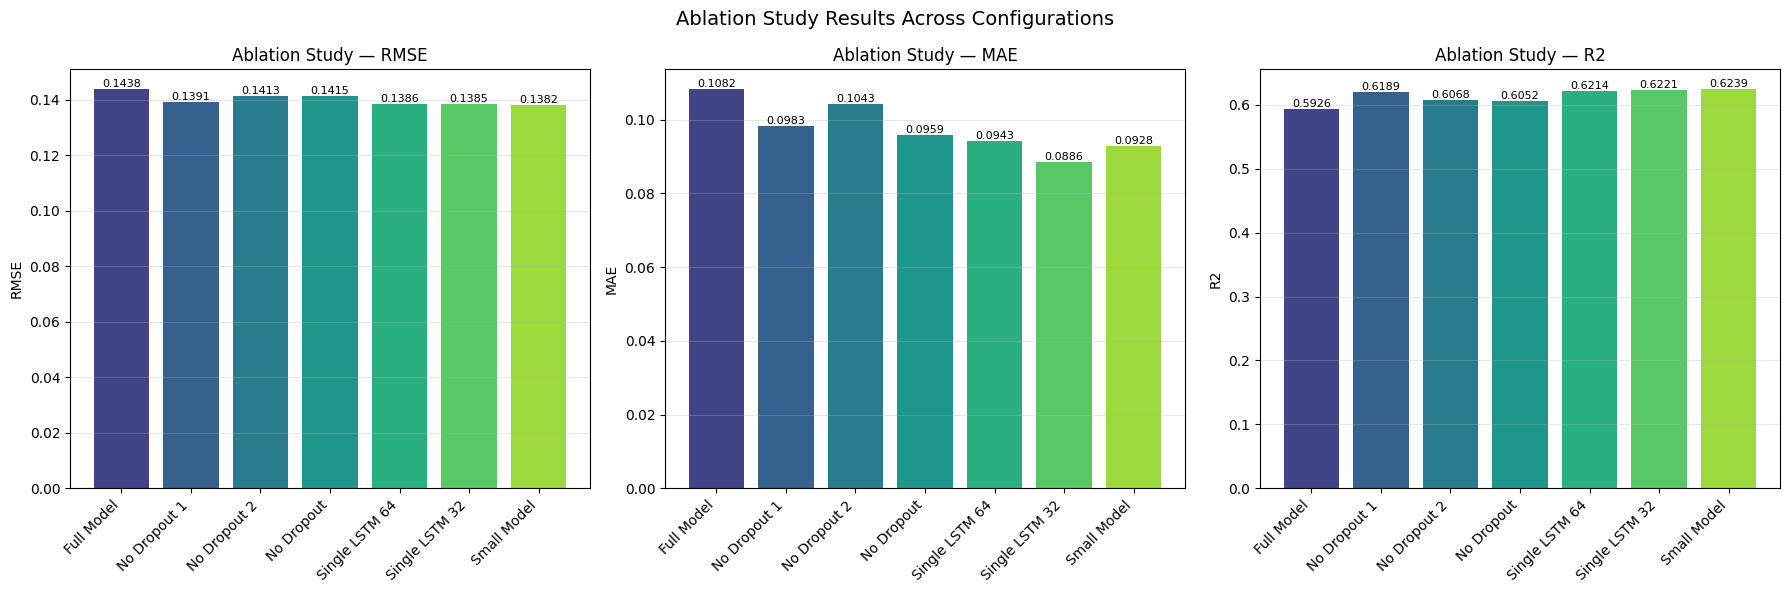

In [ ]:
# ============================================================
# ABLATION STUDY - BAR CHARTS FOR RMSE / MAE / R2
# ============================================================
import matplotlib.pyplot as plt
import numpy as np

plot_order = list(ablation_configs.keys())
plot_df = ablation_results.set_index("Experiment").loc[plot_order]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
colors = plt.cm.viridis(np.linspace(0.2, 0.85, len(plot_df)))

for ax, metric in zip(axes, ["RMSE", "MAE", "R2"]):
    x = np.arange(len(plot_df))
    bars = ax.bar(x, plot_df[metric], color=colors)
    ax.set_title(f"Ablation Study \u2014 {metric}")
    ax.set_ylabel(metric)
    ax.set_xticks(x)
    ax.set_xticklabels(plot_df.index, rotation=45, ha="right")
    ax.grid(axis="y", alpha=0.3)
    for bar, val in zip(bars, plot_df[metric]):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{val:.4f}",
                 ha="center", va="bottom", fontsize=8)

plt.suptitle("Ablation Study Results Across Configurations", fontsize=14)
plt.tight_layout()
plt.savefig("ablation_results_barcharts.png", dpi=150, bbox_inches="tight")
plt.show()

8b. Ablation Results - Impact Relative to Full Model

Shows the percentage change in each metric when a component is removed, using the Full Model as the baseline. This highlights which architectural choices actually matter, rather than just ranking raw scores.

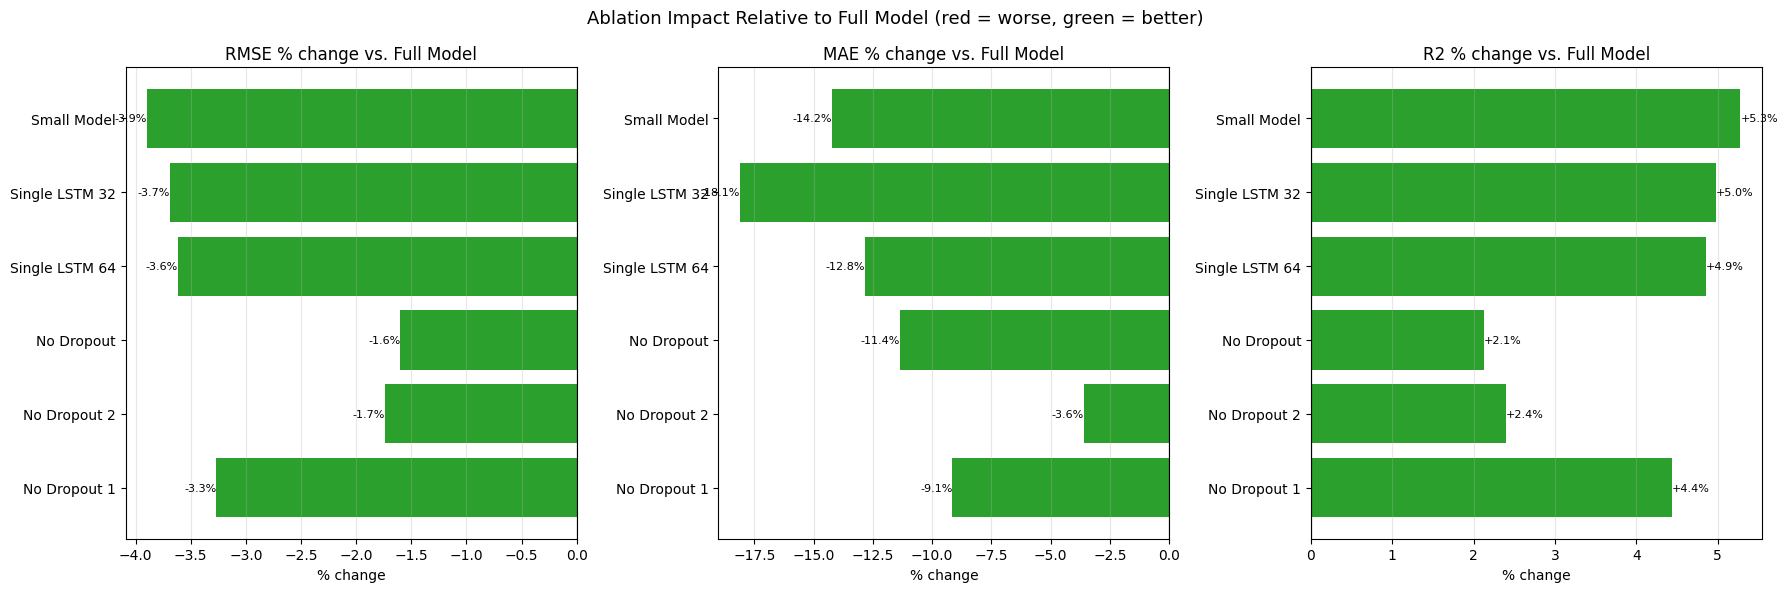

,MSE,RMSE,MAE,R2,sMAPE,RMSE_%change,MAE_%change,R2_%change
Experiment,,,,,,,,
No Dropout 1,0.02,0.14,0.10,0.62,76.15,-3.27,-9.15,4.44
No Dropout 2,0.02,0.14,0.10,0.61,77.32,-1.74,-3.60,2.40
No Dropout,0.02,0.14,0.10,0.61,82.31,-1.60,-11.37,2.13
Single LSTM 64,0.02,0.14,0.09,0.62,77.91,-3.62,-12.85,4.86
Single LSTM 32,0.02,0.14,0.09,0.62,79.14,-3.69,-18.11,4.98
Small Model,0.02,0.14,0.09,0.62,76.88,-3.89,-14.23,5.28


In [ ]:
# ============================================================
# ABLATION STUDY - % CHANGE RELATIVE TO FULL MODEL BASELINE
# ============================================================
baseline = ablation_results.set_index("Experiment").loc["Full Model"]

delta_df = ablation_results.set_index("Experiment").loc[plot_order].copy()
delta_df["RMSE_%change"] = (delta_df["RMSE"] - baseline["RMSE"]) / baseline["RMSE"] * 100
delta_df["MAE_%change"]  = (delta_df["MAE"]  - baseline["MAE"])  / baseline["MAE"]  * 100
delta_df["R2_%change"]   = (delta_df["R2"]   - baseline["R2"])   / baseline["R2"]   * 100

delta_df = delta_df.drop(index="Full Model")

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, col, label in zip(
    axes,
    ["RMSE_%change", "MAE_%change", "R2_%change"],
    ["RMSE % change", "MAE % change", "R2 % change"]
):
    vals = delta_df[col]
    bar_colors = ["#d62728" if v > 0 else "#2ca02c" for v in vals]
    # For R2, higher is better, so flip the color logic
    if col == "R2_%change":
        bar_colors = ["#2ca02c" if v > 0 else "#d62728" for v in vals]

    bars = ax.barh(delta_df.index, vals, color=bar_colors)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(label + " vs. Full Model")
    ax.set_xlabel("% change")
    ax.grid(axis="x", alpha=0.3)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2, f"{val:+.1f}%",
                 va="center", ha="left" if val >= 0 else "right", fontsize=8)

plt.suptitle("Ablation Impact Relative to Full Model (red = worse, green = better)", fontsize=13)
plt.tight_layout()
plt.savefig("ablation_results_deltas.png", dpi=150, bbox_inches="tight")
plt.show()

display(delta_df.round(2))
